# Sephora Skincare: Exploratory Data Analysis
### Products, prices and customer reviews

**Source:** Nady Inky, *Sephora Products and Skincare Reviews* (Kaggle): https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews

**Retrieved:** October 26, 2026

**License and version:** see the Kaggle dataset page (not checked inside this notebook)

## Overview
**Target audience: Sephora's skincare category manager.**
The category manager decides which skincare products and brands Sephora carries, how they are priced against the rest of their category, which items get marketing and shelf space, and which products need a quality follow-up. This analysis is written for that person.

**Why this analysis matters:**
Sephora's skincare catalog has 2,420 products and more than 1 million customer reviews. No manager can read them all, yet the reviews contain early signals about satisfaction, value for money and problems such as breakouts. This notebook turns the catalog and review data into evidence for four recurring decisions:

| Decision the category manager makes | Question this notebook answers | Section |
|---|---|---|
| **Assortment and inventory:** where to add or cut products | Which categories and price bands make up the catalog, and which are thin? | Product assortment and price positioning |
| **Pricing and brand positioning** | Do customers rate expensive products higher? Which brands sit far above their category's price? | Price, product ratings and review volume |
| **Marketing and merchandising:** what to promote | Which products combine strong ratings, popularity and fair relative price? Do labels such as "Clean" or "Vegan" go with better ratings? | Labels and feature engineering |
| **Quality follow-up and the review program** | What do unhappy customers mention, and how far can the review data be trusted? | Data quality, missingness and review text |

**Project scope:**
The catalog includes several beauty categories, but the review files cover skincare only. We therefore focus on skincare and keep product summaries separate from review summaries. The data is historical (reviews end in March 2023), so it does not show current prices or sales.

**This notebook covers (midterm):**
1. How reliable is the data, and which gaps matter for the category manager's decisions?
2. How do prices and ratings vary across categories and brands?
3. What do customers mention in their reviews?

The notebook follows the workflow: get the data through the Kaggle API, check its quality, clean it, then explore it. Supporting demonstrations that are not needed for the conclusions are in the Appendix.

## Setup

In [1]:
# Setup: libraries and chart style
import ast
import textwrap
import zipfile
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.preprocessing import MinMaxScaler

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11
})
pd.set_option("display.max_columns", 30)

## Getting the data through the Kaggle API
We download the dataset with one request to Kaggle's public datasets API (`/api/v1/datasets/download/...`). This endpoint does not page through rows: it returns the **complete dataset as a single zip archive** (the product file plus every review file), so no loop or offset parameter is needed to get all the data. The next cell saves the archive once and reuses it on later runs. The cell after it lists the archive's contents and checks that **all five review files** were read and that their row counts add up to the combined review table.

In [2]:
data_path = Path("sephora_data.zip")
download_url = "https://www.kaggle.com/api/v1/datasets/download/nadyinky/sephora-products-and-skincare-reviews"

if not data_path.exists():                  # download once, then reuse the saved file
    response = requests.get(download_url, timeout=180)
    print("Status code:", response.status_code)
    response.raise_for_status()             # stop with a clear error if the request failed
    data_path.write_bytes(response.content)
else:
    print("Using the saved file:", data_path)

Using the saved file: sephora_data.zip


In [3]:
# Read the product file and combine the review files (IDs are read as text, not numbers)
with zipfile.ZipFile(data_path) as archive:
    archive_files = archive.namelist()
    products_raw = pd.read_csv(archive.open("product_info.csv"), dtype={"product_id": "string"})
    review_files = sorted(n for n in archive_files if n.startswith("reviews_") and n.endswith(".csv"))
    review_parts = [
        pd.read_csv(archive.open(n), index_col=0, dtype={"author_id": "string", "product_id": "string"})
        for n in review_files
    ]
rows_per_review_file = pd.Series([len(part) for part in review_parts], index=review_files, name="Review rows")
reviews_raw = pd.concat(review_parts, ignore_index=True)
del review_parts

# Completeness checks: the archive must contain all five review files, and no rows may be lost
print("Files in the downloaded archive:", archive_files)
assert len(review_files) == 5, f"Expected 5 review files, found {len(review_files)}"
assert rows_per_review_file.sum() == len(reviews_raw), "Combined table does not match the file totals"
print("Review files read:", len(review_files))
print("Catalog products:", len(products_raw))
print("Raw review records:", len(reviews_raw))
display(rows_per_review_file.to_frame())
display(products_raw.head(3))
reviews_raw.head(3)

Files in the downloaded archive: ['product_info.csv', 'reviews_0-250.csv', 'reviews_1250-end.csv', 'reviews_250-500.csv', 'reviews_500-750.csv', 'reviews_750-1250.csv']
Review files read: 5
Catalog products: 8494
Raw review records: 1094411


,Review rows
reviews_0-250.csv,602130
reviews_1250-end.csv,49977
reviews_250-500.csv,206725
reviews_500-750.csv,116262
reviews_750-1250.csv,119317


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,variation_desc,ingredients,price_usd,value_price_usd,sale_price_usd,limited_edition,new,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,NaN,"['Capri Eau de Parfum:', 'Alcohol Denat. (SD A...",35.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,NaN,"['Alcohol Denat. (SD Alcohol 39C), Parfum (Fra...",195.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,NaN,"['Alcohol Denat. (SD Alcohol 39C), Parfum (Fra...",195.0,NaN,NaN,0,0,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,1741593524,5,1.0,1.0,2,0,2,2023-02-01,I use this with the Nudestix “Citrus Clean Bal...,Taught me how to double cleanse!,NaN,brown,dry,black,P504322,Gentle Hydra-Gel Face Cleanser,NUDESTIX,19.0
1,31423088263,1,0.0,NaN,0,0,0,2023-03-21,I bought this lip mask after reading the revie...,Disappointed,NaN,NaN,NaN,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
2,5061282401,5,1.0,NaN,0,0,0,2023-03-21,My review title says it all! I get so excited ...,New Favorite Routine,light,brown,dry,blonde,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0


In [4]:
# Data types and non-missing counts for both tables
products_raw.info()
reviews_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8494 entries, 0 to 8493
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          8494 non-null   string 
 1   product_name        8494 non-null   str    
 2   brand_id            8494 non-null   int64  
 3   brand_name          8494 non-null   str    
 4   loves_count         8494 non-null   int64  
 5   rating              8216 non-null   float64
 6   reviews             8216 non-null   float64
 7   size                6863 non-null   str    
 8   variation_type      7050 non-null   str    
 9   variation_value     6896 non-null   str    
 10  variation_desc      1250 non-null   str    
 11  ingredients         7549 non-null   str    
 12  price_usd           8494 non-null   float64
 13  value_price_usd     451 non-null    float64
 14  sale_price_usd      270 non-null    float64
 15  limited_edition     8494 non-null   int64  
 16  new              

## Data Quality Audit

In [5]:
# One function for both tables: how much is missing in each column?
def missing_summary(table):
    summary = pd.DataFrame({
        "Data type": table.dtypes.astype(str),
        "Missing": table.isna().sum()
    })
    summary["Missing (%)"] = (summary["Missing"] / len(table) * 100).round(2)
    return summary.sort_values("Missing (%)", ascending=False)

product_missing = missing_summary(products_raw)
review_missing = missing_summary(reviews_raw)
display(product_missing)
display(review_missing)

,Data type,Missing,Missing (%)
sale_price_usd,float64,8224,96.82
value_price_usd,float64,8043,94.69
variation_desc,str,7244,85.28
child_max_price,float64,5740,67.58
child_min_price,float64,5740,67.58
highlights,str,2207,25.98
size,str,1631,19.20
variation_value,str,1598,18.81
variation_type,str,1444,17.00
tertiary_category,str,990,11.66


,Data type,Missing,Missing (%)
helpfulness,float64,561592,51.31
review_title,str,310654,28.39
hair_color,str,226768,20.72
eye_color,str,209628,19.15
skin_tone,str,170539,15.58
is_recommended,float64,167988,15.35
skin_type,str,111557,10.19
review_text,str,1444,0.13
rating,int64,0,0.00
author_id,string,0,0.00


The tables above count `NaN` values only. A value can also be missing or wrong in other ways, so the next cell checks for blank strings, placeholder labels, duplicates and impossible numbers.

In [6]:
# Blank text ("" or spaces) is another way a value can be missing
review_text_columns = ["review_text", "review_title", "skin_type", "skin_tone", "eye_color", "hair_color"]
product_text_columns = ["product_name", "brand_name", "primary_category", "secondary_category",
                        "tertiary_category", "size", "ingredients", "highlights"]
blank_counts = {}
for col in review_text_columns:
    blank_counts["reviews: " + col] = reviews_raw[col].str.strip().eq("").sum()
for col in product_text_columns:
    blank_counts["products: " + col] = products_raw[col].str.strip().eq("").sum()
display(pd.Series(blank_counts, name="Blank strings").to_frame())

# Look for placeholder values and impossible numbers (value_counts and describe)
profile_columns = ["skin_type", "skin_tone", "eye_color", "hair_color"]
profile_values = pd.concat(
    {col: reviews_raw[col].value_counts(dropna=False) for col in profile_columns},
    names=["Field", "Value"]
)
display(profile_values.to_frame("Review records"))

print("Duplicate product IDs:", products_raw["product_id"].duplicated().sum())
print("Exact duplicate products:", products_raw.duplicated().sum())
print("Exact duplicate reviews:", reviews_raw.duplicated().sum())
display(products_raw[["price_usd", "rating", "reviews", "child_count"]].describe().round(2))
display(reviews_raw[["rating", "helpfulness", "total_feedback_count"]].describe().round(2))

,Blank strings
reviews: review_text,0
reviews: review_title,0
reviews: skin_type,0
reviews: skin_tone,0
reviews: eye_color,0
reviews: hair_color,0
products: product_name,0
products: brand_name,0
products: primary_category,0
products: secondary_category,0


Review records
Field      Value                      
skin_type  combination          544513
           dry                  185937
           normal               131910
           oily                 120494
           nan                  111557
skin_tone  light                266418
           fair                 208034
           lightMedium          196541
           nan                  170539
           medium                70486
           mediumTan             62456
           fairLight             56228
           tan                   33678
           deep                  20601
           rich                   5493
           olive                  1730
           porcelain              1612
           dark                    522
           notSureST                70
           ebony                     3
eye_color  brown                471181
           nan                  209628
           blue                 172022
           hazel                118194
           green                117906
           Grey                   4859
           gray                    621
hair_color brown                403099
           nan                  226768
           blonde               203255
           black                188404
           auburn                31146
           red                   25777
           brunette              10541
           gray                   5421

Duplicate product IDs: 0
Exact duplicate products: 0
Exact duplicate reviews: 224


,price_usd,rating,reviews,child_count
count,8494.00,8216.00,8216.00,8494.00
mean,51.66,4.19,448.55,1.63
std,53.67,0.52,1101.98,5.38
min,3.00,1.00,1.00,0.00
25%,25.00,3.98,26.00,0.00
50%,35.00,4.29,122.00,0.00
75%,58.00,4.53,418.00,1.00
max,1900.00,5.00,21281.00,105.00


,rating,helpfulness,total_feedback_count
count,1094411.00,532819.00,1094411.00
mean,4.30,0.77,4.18
std,1.15,0.32,22.72
min,1.00,0.00,0.00
25%,4.00,0.65,0.00
50%,5.00,0.93,0.00
75%,5.00,1.00,3.00
max,5.00,1.00,5464.00


**What we found: data reliability**

**Can we trust the data?**
- Product names, brands and prices are fully complete, so every review can be matched to the right product and price
- 97% of skincare products have customer reviews (see the skincare scope section), a strong base for category decisions
- Catalog ratings are missing for only 3.3% of all products (2.9% of skincare products), so rating comparisons cover almost every product. Complete fields support the analysis but do not establish that ratings are unbiased, because customers choose whether to write a review
- No invalid values were found (next section): no prices at or below zero, no ratings outside 1-5 and no impossible feedback counts

**Which gaps could affect business decisions?**
- 15.4% of reviews have no recommendation response. The gap varies by category, from about 3% for self tanners to 26% for lip balms, so recommendation rates for categories with large gaps (lip balms, cleansers, masks) rest on fewer answers and should be read with their response coverage
- Optional customer-profile fields have the largest review gaps: hair color 20.7%, eye color 19.1%, skin tone 15.6% and skin type 10.2%. These mean "not provided", not errors
- The biggest catalog gaps (sale price 96.8%, value price 94.7%, variation description 85.3%, child prices 67.6%) are fields that apply only to some products

**Note**
- There are no blank strings and no duplicate product IDs, but there are **224 exact duplicate reviews**
- **Disguised values:** `skin_tone` contains the placeholder `notSureST` (70 reviews), and `eye_color` has both `Grey` (4,859) and `gray` (621), which are the same label

## Cleaning, validation and missing-data decisions

In [7]:
# Keep the raw tables untouched and work on copies
products = products_raw.copy()
reviews = reviews_raw.drop_duplicates().copy()      # remove exact duplicate reviews only

# Standardize labels
for col in ["brand_name", "primary_category", "secondary_category"]:
    products[col] = products[col].str.strip()
reviews["skin_type"] = reviews["skin_type"].str.strip().str.lower()
reviews["eye_color"] = (                                                   # Grey, grey and gray become one label
    reviews["eye_color"].str.strip().str.lower().replace("grey", "gray")
)
reviews["skin_tone"] = reviews["skin_tone"].replace("notSureST", np.nan)  # placeholder -> real missing value
reviews["submission_time"] = pd.to_datetime(reviews["submission_time"], errors="coerce")

# Missingness is a variable too: flag it instead of guessing the value
reviews["recommendation_missing"] = reviews["is_recommended"].isna()
reviews["skin_type_missing"] = reviews["skin_type"].isna()
reviews["text_missing"] = reviews["review_text"].isna()
reviews["skin_type_group"] = reviews["skin_type"].fillna("Unknown")

print("Exact duplicate reviews removed:", len(reviews_raw) - len(reviews))
print("notSureST left in skin_tone:", (reviews["skin_tone"] == "notSureST").sum())
print("Eye color labels after cleaning:", sorted(reviews["eye_color"].dropna().unique()))

Exact duplicate reviews removed: 224
notSureST left in skin_tone: 0
Eye color labels after cleaning: ['blue', 'brown', 'gray', 'green', 'hazel']


In [8]:
# Validation: count values that cannot be right
def count_outside(series, low, high):
    """Count known values outside the allowed range."""
    return (series.notna() & ~series.between(low, high)).sum()

checks = pd.Series({
    "Product prices at or below 0": (products["price_usd"] <= 0).sum(),
    "Product ratings outside 1-5": count_outside(products["rating"], 1, 5),
    "Review ratings outside 1-5": count_outside(reviews["rating"], 1, 5),
    "Recommendation flags not 0 or 1": (reviews["is_recommended"].notna() & ~reviews["is_recommended"].isin([0, 1])).sum(),
    "Helpfulness outside 0-1": count_outside(reviews["helpfulness"], 0, 1),
    "Dates that could not be read": reviews["submission_time"].isna().sum(),
    "Negative review or feedback counts": (products["reviews"] < 0).sum() + (reviews["total_feedback_count"] < 0).sum(),
    "Feedback totals that do not add up": (
        reviews["total_feedback_count"] != reviews["total_pos_feedback_count"] + reviews["total_neg_feedback_count"]
    ).sum()
}, name="Records")
display(checks.to_frame())

# Some gaps are expected: they simply do not apply
structural_checks = pd.Series({
    "Missing helpfulness": reviews["helpfulness"].isna().sum(),
    "Missing helpfulness with zero feedback": (reviews["helpfulness"].isna() & reviews["total_feedback_count"].eq(0)).sum(),
    "Missing sale price": products["sale_price_usd"].isna().sum(),
    "Missing child price with no child products": (products["child_min_price"].isna() & products["child_count"].eq(0)).sum(),
    "Missing child price despite child products": (products["child_min_price"].isna() & products["child_count"].gt(0)).sum()
}, name="Records")
display(structural_checks.to_frame())

,Records
Product prices at or below 0,0
Product ratings outside 1-5,0
Review ratings outside 1-5,0
Recommendation flags not 0 or 1,0
Helpfulness outside 0-1,0
Dates that could not be read,0
Negative review or feedback counts,0
Feedback totals that do not add up,0


,Records
Missing helpfulness,561466
Missing helpfulness with zero feedback,561466
Missing sale price,8224
Missing child price with no child products,5740
Missing child price despite child products,0


In [9]:
# Drop columns that are mostly empty
# Key columns stay even if sparse; the cut-off is a rule of thumb, not a law
keep = ["price_usd", "rating", "reviews", "highlights", "ingredients"]
mostly_empty = product_missing.index[(product_missing["Missing (%)"] > 50) & ~product_missing.index.isin(keep)]
print("Dropped from the product table:", list(mostly_empty))
products = products.drop(columns=mostly_empty)

Dropped from the product table: ['sale_price_usd', 'value_price_usd', 'variation_desc', 'child_max_price', 'child_min_price']


### Tidy data check
| Tidy rule broken | Where | Fix |
|---|---|---|
| One observational unit in several tables | Reviews arrive in several `reviews_*.csv` files | `pd.concat` into one table |
| Several values in one column | `highlights` holds a list of labels | Parse, then `explode` to one label per row |
| Values in column headers | `brand_mix` crosstab has categories as columns | `melt` to a long table (Appendix A) |
| Two observational units mixed | Products vs. reviews | Kept as two tables and joined on `product_id` |

### Cleaning decisions

| Information | What we do | Why |
|---|---|---|
| Exact duplicate reviews | Remove them | Avoid counting the same record twice |
| Placeholder `notSureST` | Set to missing | It means "not sure", not a real skin tone |
| Eye color `Grey` / `gray` | Lowercase, then map `grey` to `gray` | One label for one color (lowercasing alone leaves `grey` and `gray` apart) |
| Price and rating | Keep unknown values, exclude them only when needed | Avoid inventing values |
| Review counts | Keep missing values | Unknown does not mean zero |
| Review text | Keep reviews for numeric analysis | A rating is useful without text |
| Recommendation | Calculate rates from known responses | A missing response is not a "no" |
| Helpfulness | Keep missing when there are no votes | No votes cannot give a score |
| Customer profiles | Keep missing, show an "Unknown" group | Keep useful reviews without guessing |
| Sale and variant prices | Keep missing where not applicable | Some products have no sale or variants |

**Results**
- The checks found no invalid values, so nothing needed fixing
- Removing 224 exact duplicates leaves 1,094,187 reviews
- All 561,466 missing helpfulness scores belong to reviews with no feedback votes
- All 5,740 missing child minimum prices belong to products with no child variants
- There is no unique review ID, so we cannot confirm whether identical rows are separate reviews

## Skincare scope and joining the tables

In [10]:
# Which products are skincare, and do the review files match the catalog?
skincare_products = products[products["primary_category"] == "Skincare"].copy()
skincare_ids = skincare_products["product_id"]

scope = pd.Series({
    "All catalog products": len(products),
    "Skincare catalog products": len(skincare_products),
    "Cleaned review records": len(reviews),
    "Distinct products in reviews": reviews["product_id"].nunique(),
    "Review rows with no catalog match": (~reviews["product_id"].isin(products["product_id"])).sum(),
    "Review rows outside skincare": (~reviews["product_id"].isin(skincare_ids)).sum()
}, name="Count")
scope.to_frame()

,Count
All catalog products,8494
Skincare catalog products,2420
Cleaned review records,1094187
Distinct products in reviews,2351
Review rows with no catalog match,0
Review rows outside skincare,0


In [11]:
# Join: many reviews belong to one product, so merge on product_id
product_attributes = skincare_products[[
    "product_id", "brand_name", "secondary_category", "tertiary_category",
    "price_usd", "rating", "reviews", "out_of_stock"
]].rename(columns={"rating": "catalog_rating", "reviews": "catalog_review_count"})

skincare_reviews = reviews[reviews["product_id"].isin(skincare_ids)].rename(
    columns={"rating": "review_rating", "price_usd": "review_price_usd"}
)
skincare_reviews = skincare_reviews.drop(columns=["brand_name", "product_name"])   # use the catalog versions

rows_before = len(skincare_reviews)
skincare_reviews = skincare_reviews.merge(product_attributes, on="product_id", how="left")
print("Review rows before and after the merge:", rows_before, len(skincare_reviews))   # must be equal

price_gap = (skincare_reviews["review_price_usd"] - skincare_reviews["price_usd"]).abs()
print("Price disagreements between the tables:", (price_gap > 0.01).sum())
print("Review date range:", skincare_reviews["submission_time"].min(), "to", skincare_reviews["submission_time"].max())

Review rows before and after the merge: 1094187 1094187
Price disagreements between the tables: 0
Review date range: 2008-08-28 00:00:00 to 2023-03-21 00:00:00


In [12]:
# Missing-data summary for skincare only (the scope of every later analysis)
# Products: use the raw skincare rows so the columns dropped earlier are still visible
skincare_products_raw = products_raw[products_raw["primary_category"] == "Skincare"]
skincare_product_missing = missing_summary(skincare_products_raw).join(
    product_missing["Missing (%)"].rename("All categories (%)")
)
skincare_product_missing = skincare_product_missing.rename(columns={"Missing (%)": "Skincare (%)"})
display(skincare_product_missing[skincare_product_missing["Missing"] > 0])

# Reviews: original review fields only (the review files are all skincare, after duplicate removal)
original_review_columns = [c for c in reviews_raw.columns]
skincare_review_missing = missing_summary(reviews.loc[reviews["product_id"].isin(skincare_ids), original_review_columns])
display(skincare_review_missing[skincare_review_missing["Missing"] > 0])

,Data type,Missing,Skincare (%),All categories (%)
variation_desc,str,2407,99.46,85.28
sale_price_usd,float64,2375,98.14,96.82
value_price_usd,float64,2258,93.31,94.69
child_max_price,float64,2018,83.39,67.58
child_min_price,float64,2018,83.39,67.58
variation_value,str,420,17.36,18.81
highlights,str,417,17.23,25.98
tertiary_category,str,380,15.70,11.66
variation_type,str,372,15.37,17.00
size,str,365,15.08,19.20


,Data type,Missing,Missing (%)
helpfulness,float64,561466,51.31
review_title,str,310625,28.39
hair_color,str,226649,20.71
eye_color,str,209510,19.15
skin_tone,str,170498,15.58
is_recommended,float64,167873,15.34
skin_type,str,111449,10.19
review_text,str,1444,0.13


- The catalog has 8,494 products, including 2,420 skincare products
- The review files cover 2,351 skincare products (97.1%). All review product IDs match skincare products in the catalog
- The merge keeps every review row and prices agree in both tables
- Reviews run from August 28, 2008 to March 21, 2023
- The 69 skincare products without reviews stay in the assortment and price analysis
- Product-level questions use the product table, so each product is counted once
- **Skincare missing data:** the skincare-only summary shows the same pattern as the full catalog. Prices, names and brands are complete; 69 skincare products (2.9%) have no rating or review count, 134 (5.5%) have no ingredient list and 365 (15.1%) have no size. Because the review files are all skincare, the review gaps match the audit above
- **For the category manager:** review-based metrics are available for almost every skincare product. Missing sizes mean price per ounce cannot yet be compared across products, and the 69 unreviewed products are candidates for review-sampling programs

## Missingness diagnosis and sensitivity analysis
For each field with gaps we ask: **do the rows with missing values differ from the rest?** Missing rates that vary across observed groups raise concerns about assuming the gaps are completely random, but these comparisons alone cannot identify the mechanism behind them.

In [13]:
missing_flags = ["recommendation_missing", "skin_type_missing", "text_missing"]

missing_by_rating = skincare_reviews.groupby("review_rating")[missing_flags].mean() * 100
display(missing_by_rating.round(2))

missing_by_category = skincare_reviews.groupby("secondary_category")[missing_flags].mean() * 100
missing_by_category["Reviews"] = skincare_reviews.groupby("secondary_category").size()
display(missing_by_category.round(2))

,recommendation_missing,skin_type_missing,text_missing
review_rating,,,
1,14.26,11.20,0.19
2,14.65,10.31,0.14
3,12.74,8.66,0.08
4,14.64,9.34,0.09
5,15.99,10.51,0.14


,recommendation_missing,skin_type_missing,text_missing,Reviews
secondary_category,,,,
Cleansers,21.50,11.43,0.15,200565
Eye Care,11.75,7.23,0.11,74991
High Tech Tools,5.64,8.20,0.08,5925
Lip Balms & Treatments,25.93,15.23,0.23,61660
Masks,19.53,19.50,0.14,70527
Mini Size,9.84,6.06,0.12,85489
Moisturizers,17.09,11.45,0.10,297343
Self Tanners,2.86,3.61,0.13,11942
Shop by Concern,0.00,0.00,0.00,15


**What the pattern tells us**

- **Missingness varies across observed groups, which raises concerns about assuming completely random gaps.**
  Recommendation missing rates range from 3% for self tanners to 26% for lip balms (21.5% for cleansers, 19.5% for masks), but only from 12.7% to 16.0% across star ratings. Recommendation rates for lip balms, cleansers and masks rest on fewer answers and should be read with their response coverage.

- **These comparisons cannot distinguish MAR from MNAR.**
  A gap that depends on category could also depend on the unobserved answer itself, for example if dissatisfied customers skip the question. The sensitivity analysis below shows how far the overall recommendation rate could move under different assumptions.

- **Review text is nearly complete, but completeness does not establish representativeness.**
  Only 0.13% of reviews lack text, so almost every review can be analyzed. That does not mean reviewers represent all Sephora customers, because customers choose whether to write a review.

In [14]:
# What happens if we keep only complete rows? (deletion)
core_review_fields = ["review_rating", "review_text", "skin_type", "is_recommended"]
complete_reviews = skincare_reviews.dropna(subset=core_review_fields)
sample_comparison = pd.DataFrame({
    "All cleaned skincare reviews": [
        len(skincare_reviews), skincare_reviews["review_rating"].mean(),
        skincare_reviews["review_rating"].le(2).mean() * 100
    ],
    "Complete on rating, text, skin type and recommendation": [
        len(complete_reviews), complete_reviews["review_rating"].mean(),
        complete_reviews["review_rating"].le(2).mean() * 100
    ]
}, index=["Review records", "Mean rating", "Low-rating share (%)"]).T
sample_comparison.round(3)

,Review records,Mean rating,Low-rating share (%)
All cleaned skincare reviews,1094187.0,4.299,10.441
"Complete on rating, text, skin type and recommendation",905842.0,4.291,10.485


In [15]:
# Sensitivity analysis: what if every missing response were "no", half and half, or "yes"?
# These are scenarios, not recovered answers or confidence intervals.
known_yes = skincare_reviews["is_recommended"].eq(1).sum()
unknown = skincare_reviews["is_recommended"].isna().sum()
scenarios = pd.DataFrame({"Assumed recommendation rate among missing responses": [0, 0.5, 1]})
scenarios["Overall recommendation rate (%)"] = (
    (known_yes + unknown * scenarios["Assumed recommendation rate among missing responses"])
    / len(skincare_reviews) * 100
)
scenarios.round(2)

,Assumed recommendation rate among missing responses,Overall recommendation rate (%)
0,0.0,71.11
1,0.5,78.78
2,1.0,86.45


In [16]:
# Do products WITHOUT a catalog rating differ from rated ones?
skincare_products["rating_missing"] = skincare_products["rating"].isna()
compare_cols = [c for c in ["price_usd", "loves_count", "child_count"] if c in skincare_products]
display(skincare_products.groupby("rating_missing")[compare_cols].median().round(1))
display((pd.crosstab(skincare_products["secondary_category"], skincare_products["rating_missing"],
                     normalize="index") * 100).round(1).sort_values(True, ascending=False).head(8))

,price_usd,loves_count,child_count
rating_missing,,,
False,44.0,10478.0,0.0
True,64.0,352.0,0.0


rating_missing,False,True
secondary_category,,
Value & Gift Sets,86.7,13.3
High Tech Tools,95.0,5.0
Treatments,97.0,3.0
Moisturizers,97.6,2.4
Cleansers,98.1,1.9
Mini Size,98.2,1.8
Eye Care,98.9,1.1
Masks,99.4,0.6


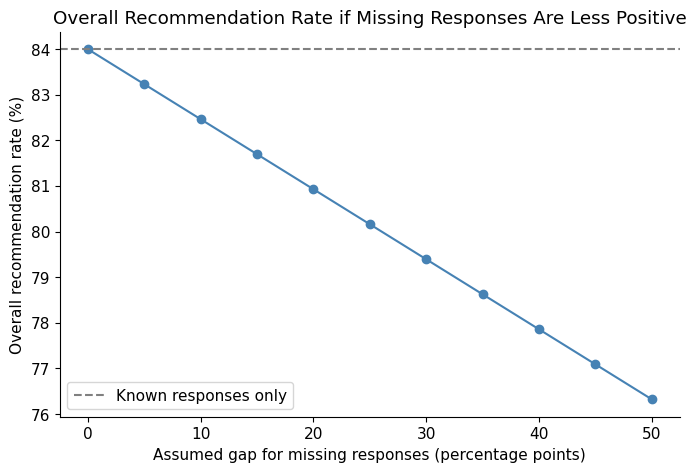

In [17]:
# MNAR sensitivity: assume reviewers who skipped the
# question recommend at a rate delta points BELOW those who answered
p_known = skincare_reviews["is_recommended"].mean()
n_all = len(skincare_reviews)
deltas = np.arange(0, 0.51, 0.05)
overall = [(known_yes + unknown * max(p_known - d, 0)) / n_all * 100 for d in deltas]

plt.plot(deltas * 100, overall, marker="o", color="steelblue")
plt.axhline(p_known * 100, ls="--", color="grey", label="Known responses only")
plt.title("Overall Recommendation Rate if Missing Responses Are Less Positive")
plt.xlabel("Assumed gap for missing responses (percentage points)")
plt.ylabel("Overall recommendation rate (%)")
plt.legend()
plt.show()

- **Unrated products are not typical:** their median price is 64 USD against 44 USD for rated products, they have far fewer loves (median 352 against 10,478), and they are concentrated in Value & Gift Sets (13.3% unrated). They look like newer or niche items, so we leave them out of rating analyses instead of filling them in. Imputation comparisons for these ratings are in Appendix D
- **Sensitivity to less positive non-responders:** if reviewers who skipped the question recommend 10 points less often than those who answered, the overall recommendation rate falls from 84.0% to about 82.5%; with a 50-point gap it is about 76.3%. This 76.3%-84.0% range applies only to these selected scenarios
- **For the category manager:** recommendation rates should always be reported with their response coverage, especially for categories with large gaps

- Requiring all four core review fields (rating, review text, skin type and recommendation) keeps 905,842 reviews (82.8%), and the mean rating barely changes (4.299 to 4.291). Overall ratings look stable, although smaller groups may change
- Among known responses, 84.0% recommend the product
- **Full scenario range:** if every missing response were "no", the overall rate would be 71.1%; if every one were "yes", 86.5%. These are bounds under assumptions, not a confidence interval, and they are wider than the 76.3%-84.0% range from the less-positive scenarios above
- The main analysis keeps the unknown responses unknown. Fill-in demonstrations are in Appendix D

## Product assortment and price positioning

,Products,Median_price_USD,Rated_products,Mean_catalog_rating,Share (%)
secondary_category,,,,,
Moisturizers,551,58.0,538,4.28,22.77
Treatments,466,58.0,452,4.31,19.26
Cleansers,361,34.0,354,4.31,14.92
Value & Gift Sets,196,48.0,170,4.12,8.1
Eye Care,186,58.0,184,4.11,7.69
Masks,166,40.5,165,4.26,6.86
Mini Size,112,21.0,110,4.11,4.63
Sunscreen,108,36.0,108,4.12,4.46
High Tech Tools,80,92.0,76,4.14,3.31


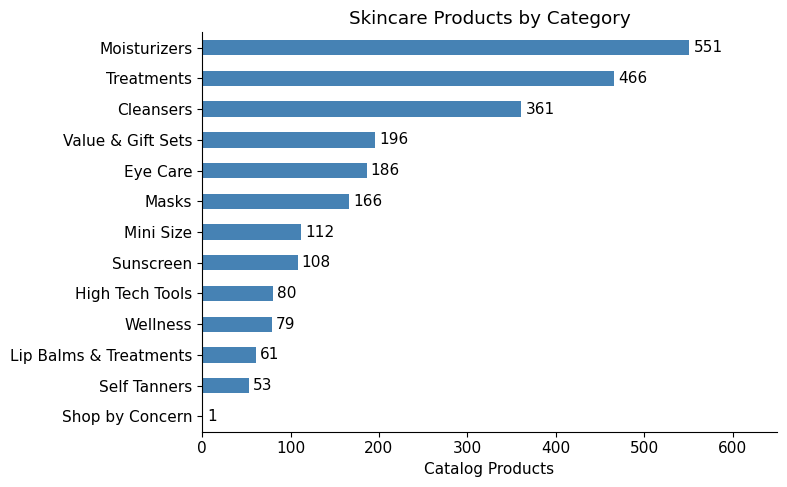

In [18]:
# Product-level summary: one row per product, so each product counts once
category_summary = skincare_products.groupby("secondary_category", dropna=False).agg(
    Products=("product_id", "size"),
    Median_price_USD=("price_usd", "median"),
    Rated_products=("rating", "count"),
    Mean_catalog_rating=("rating", "mean")
)
category_summary["Share (%)"] = category_summary["Products"] / len(skincare_products) * 100
display(category_summary.round(2).sort_values("Products", ascending=False))

category_counts = category_summary["Products"].sort_values()
ax = category_counts.plot.barh(color="steelblue")
ax.bar_label(ax.containers[0], padding=3)
plt.xlim(0, category_counts.max() * 1.18)
plt.title("Skincare Products by Category")
plt.xlabel("Catalog Products")
plt.ylabel("")
plt.tight_layout()
plt.show()

count    2420.00
mean       60.51
std        69.75
min         3.00
25%        28.00
50%        44.00
75%        70.00
max      1900.00
Name: price_usd, dtype: float64

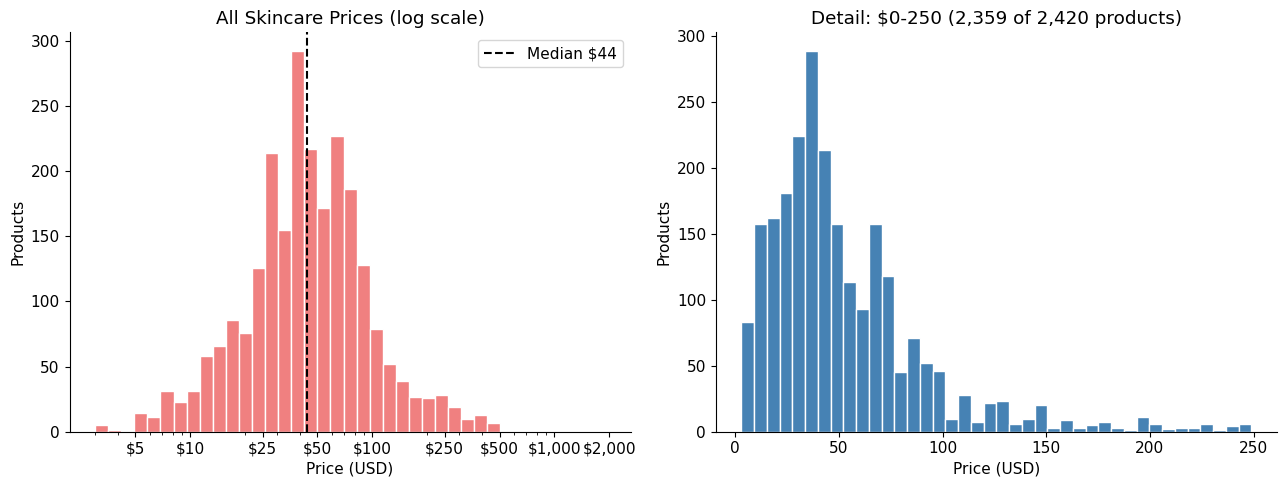

,product_name,brand_name,secondary_category,price_usd
6802,Shani Darden by Déesse PRO LED Light Mask,Shani Darden Skin Care,High Tech Tools,1900.0
5556,NuFACE Trinity+ & Effective Lip and Eye Attach...,NuFACE,High Tech Tools,495.0
2162,DRx SpectraLite BodyWare Pro,Dr. Dennis Gross Skincare,High Tech Tools,465.0
3510,Touch Home Permanent Hair Removal Device,iluminage,High Tech Tools,449.0
5545,Trinity + Eye and Lip Enhancer Attachment Bundle,NuFACE,High Tech Tools,449.0


In [19]:
# Prices: high-priced products are plausible records, so they are retained
skincare_prices = skincare_products["price_usd"]
display(skincare_prices.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Left: every product on a log scale, so the long right tail and the bulk are both visible
log_bins = np.logspace(np.log10(skincare_prices.min()), np.log10(skincare_prices.max()), 40)
axes[0].hist(skincare_prices, bins=log_bins, color="lightcoral", edgecolor="white")
axes[0].set_xscale("log")
price_ticks = [5, 10, 25, 50, 100, 250, 500, 1000, 2000]
axes[0].set_xticks(price_ticks)
axes[0].set_xticklabels([f"${t:,}" for t in price_ticks])
axes[0].axvline(skincare_prices.median(), color="black", ls="--", label=f"Median ${skincare_prices.median():.0f}")
axes[0].legend()
axes[0].set_title("All Skincare Prices (log scale)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Products")
# Right: linear detail of the range where most products sit
shown = skincare_prices.le(250).sum()
axes[1].hist(skincare_prices[skincare_prices.le(250)], bins=40, color="steelblue", edgecolor="white")
axes[1].set_title(f"Detail: $0-250 ({shown:,} of {len(skincare_prices):,} products)")
axes[1].set_xlabel("Price (USD)")
axes[1].set_ylabel("Products")
plt.tight_layout()
plt.show()
display(skincare_products.nlargest(5, "price_usd")[["product_name", "brand_name", "secondary_category", "price_usd"]])

In [20]:
# Turn prices into bands with pd.cut. Bins are right-closed: each band includes its upper edge,
# so a $25.00 product is in "$25 or less" and a $25.01 product is in "$25.01-50"
skincare_products["price_band"] = pd.cut(
    skincare_products["price_usd"],
    bins=[0, 25, 50, 100, np.inf],
    labels=["$25 or less", "$25.01-50", "$50.01-100", "Over $100"],
    include_lowest=True
)
price_band_summary = skincare_products.groupby("price_band", observed=True).agg(
    Products=("product_id", "size"),
    Rated_products=("rating", "count"),
    Min_price_USD=("price_usd", "min"),
    Max_price_USD=("price_usd", "max"),
    Median_price_USD=("price_usd", "median"),
    Mean_catalog_rating=("rating", "mean"),
    Median_review_count=("reviews", "median")
)
price_band_summary["Share (%)"] = price_band_summary["Products"] / len(skincare_products) * 100
price_band_summary.round(2)

,Products,Rated_products,Min_price_USD,Max_price_USD,Median_price_USD,Mean_catalog_rating,Median_review_count,Share (%)
price_band,,,,,,,,
$25 or less,528,522,3.0,25.0,16.0,4.12,122.5,21.82
$25.01-50,904,881,26.0,50.0,38.0,4.25,199.0,37.36
$50.01-100,728,704,51.0,100.0,69.0,4.30,181.0,30.08
Over $100,260,244,102.0,1900.0,159.0,4.20,60.0,10.74


In [21]:
# Compare each product with the median price of its own category (groupby + transform)
skincare_products["category_median_price"] = skincare_products.groupby("secondary_category")["price_usd"].transform("median")
skincare_products["relative_price"] = skincare_products["price_usd"] / skincare_products["category_median_price"]

brand_summary = skincare_products.groupby("brand_name").agg(
    Products=("product_id", "size"),
    Rated_products=("rating", "count"),
    Median_price_USD=("price_usd", "median"),
    Mean_catalog_rating=("rating", "mean"),
    Median_relative_price=("relative_price", "median")
)
display(brand_summary.sort_values("Products", ascending=False).head(15).round(2))

# Brands with at least 20 products, most expensive relative to their categories
# (a size cut-off for description, not a statistical guarantee)
established = brand_summary["Products"] >= 20
display(brand_summary[established].sort_values("Median_relative_price", ascending=False).head(10).round(2))

,Products,Rated_products,Median_price_USD,Mean_catalog_rating,Median_relative_price
brand_name,,,,,
SEPHORA COLLECTION,96,96,14.00,4.05,0.30
CLINIQUE,90,88,34.75,4.03,0.78
Peter Thomas Roth,58,56,55.00,4.16,1.12
Shiseido,56,49,65.00,4.22,1.29
Kiehl's Since 1851,53,46,46.00,4.24,1.03
fresh,50,48,39.50,4.22,1.10
Dermalogica,48,48,64.50,4.53,1.28
Murad,48,46,51.00,4.32,1.24
The Ordinary,45,45,10.00,4.18,0.18


,Products,Rated_products,Median_price_USD,Mean_catalog_rating,Median_relative_price
brand_name,,,,,
La Mer,33,33,200.0,4.15,4.52
Dr. Barbara Sturm,39,38,150.0,4.01,3.71
Tata Harper,30,28,88.0,4.10,2.24
Dior,29,29,85.0,4.25,1.76
Lancôme,31,29,82.0,4.32,1.47
Estée Lauder,34,33,72.0,4.23,1.41
goop,23,23,58.0,3.97,1.41
Sulwhasoo,25,21,72.0,4.53,1.38
Algenist,32,31,78.0,4.15,1.34


In [22]:
# Category mix inside the five largest brands (the tidy long version is in Appendix A)
top_brands = brand_summary["Products"].nlargest(5).index
top_brand_products = skincare_products[skincare_products["brand_name"].isin(top_brands)]
brand_mix = pd.crosstab(
    top_brand_products["brand_name"], top_brand_products["secondary_category"], normalize="index"
) * 100
brand_mix.round(1)

secondary_category,Cleansers,Eye Care,High Tech Tools,Lip Balms & Treatments,Masks,Mini Size,Moisturizers,Self Tanners,Sunscreen,Treatments,Value & Gift Sets,Wellness
brand_name,,,,,,,,,,,,
CLINIQUE,25.6,10.0,1.1,2.2,3.3,2.2,27.8,1.1,5.6,13.3,7.8,0.0
Kiehl's Since 1851,20.8,5.7,0.0,1.9,7.5,7.5,26.4,0.0,1.9,18.9,9.4,0.0
Peter Thomas Roth,6.9,15.5,0.0,0.0,10.3,6.9,12.1,0.0,6.9,31.0,10.3,0.0
SEPHORA COLLECTION,12.5,3.1,9.4,4.2,21.9,0.0,6.2,2.1,1.0,18.8,5.2,15.6
Shiseido,16.1,10.7,0.0,0.0,3.6,1.8,28.6,0.0,23.2,8.9,7.1,0.0


In [23]:
# Distribution shape
price = skincare_products["price_usd"]
shape = pd.Series({
    "Mean": price.mean(), "Median": price.median(), "Mode": price.mode()[0],
    "1st percentile": price.quantile(0.01), "99th percentile": price.quantile(0.99),
    "Skew (raw)": price.skew(), "Skew (log)": np.log(price).skew(),
})
display(shape.round(2).to_frame("Price (USD)"))

# Outliers with the IQR rule: flag, don't delete (high prices are plausible records)
q1, q3 = price.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
skincare_products["price_outlier"] = price > upper
print(f"IQR upper fence: ${upper:,.0f}; flagged products: {skincare_products['price_outlier'].sum()}")
display(skincare_products.loc[skincare_products["price_outlier"], "secondary_category"].value_counts().head(8))

,Price (USD)
Mean,60.51
Median,44.00
Mode,38.00
1st percentile,6.00
99th percentile,320.00
Skew (raw),9.53
Skew (log),0.03


IQR upper fence: $133; flagged products: 170


secondary_category
Moisturizers         50
Treatments           35
High Tech Tools      35
Value & Gift Sets    19
Eye Care             16
Masks                 8
Sunscreen             3
Mini Size             2
Name: count, dtype: int64

In [24]:
# Compare outliers within each category: a $150 device is normal, a $150 lip balm is not
category_prices = skincare_products.groupby("secondary_category")["price_usd"]
category_q1 = category_prices.transform(lambda s: s.quantile(0.25))
category_q3 = category_prices.transform(lambda s: s.quantile(0.75))
skincare_products["category_price_outlier"] = skincare_products["price_usd"] > category_q3 + 1.5 * (category_q3 - category_q1)

outlier_comparison = skincare_products.groupby("secondary_category").agg(
    Products=("product_id", "size"),
    Median_price_USD=("price_usd", "median"),
    Max_price_USD=("price_usd", "max"),
    Global_IQR_outliers=("price_outlier", "sum"),
    Within_category_outliers=("category_price_outlier", "sum")
)
display(outlier_comparison.sort_values("Within_category_outliers", ascending=False))

# The products that are most expensive relative to their own category, with their ratings
display(skincare_products.loc[skincare_products["category_price_outlier"],
        ["product_name", "brand_name", "secondary_category", "price_usd", "relative_price", "rating", "reviews"]]
        .sort_values("relative_price", ascending=False).head(10).round(2))

,Products,Median_price_USD,Max_price_USD,Global_IQR_outliers,Within_category_outliers
secondary_category,,,,,
Moisturizers,551,58.0,400.0,50,44
Cleansers,361,34.0,135.0,1,34
Treatments,466,58.0,425.0,35,21
Eye Care,186,58.0,300.0,16,19
Value & Gift Sets,196,48.0,380.0,19,18
Sunscreen,108,36.0,270.0,3,13
Mini Size,112,21.0,220.0,2,12
Masks,166,40.5,300.0,8,9
Lip Balms & Treatments,61,24.0,95.0,0,4


,product_name,brand_name,secondary_category,price_usd,relative_price,rating,reviews
6802,Shani Darden by Déesse PRO LED Light Mask,Shani Darden Skin Care,High Tech Tools,1900.0,20.65,3.75,4.0
4341,Mini The Concentrate Serum,La Mer,Mini Size,220.0,10.48,4.44,18.0
4343,Crème de La Mer Duet,La Mer,Value & Gift Sets,380.0,7.92,4.46,13.0
6866,Future Solution LX Total Protective Emulsion B...,Shiseido,Sunscreen,270.0,7.50,4.00,2.0
6865,Future Solution LX Total Protective Cream Broa...,Shiseido,Sunscreen,270.0,7.50,5.00,2.0
4335,The Lifting and Firming Mask,La Mer,Masks,300.0,7.41,4.29,42.0
4313,The Concentrate Serum,La Mer,Treatments,425.0,7.33,4.52,563.0
8424,The Youth Vault: 13-Piece Vegan Skincare + App...,Youth To The People,Value & Gift Sets,340.0,7.08,4.88,8.0
4320,The Regenerating Serum,La Mer,Treatments,410.0,7.07,4.38,152.0
4344,Mini The Renewal Oil,La Mer,Mini Size,145.0,6.90,4.31,13.0


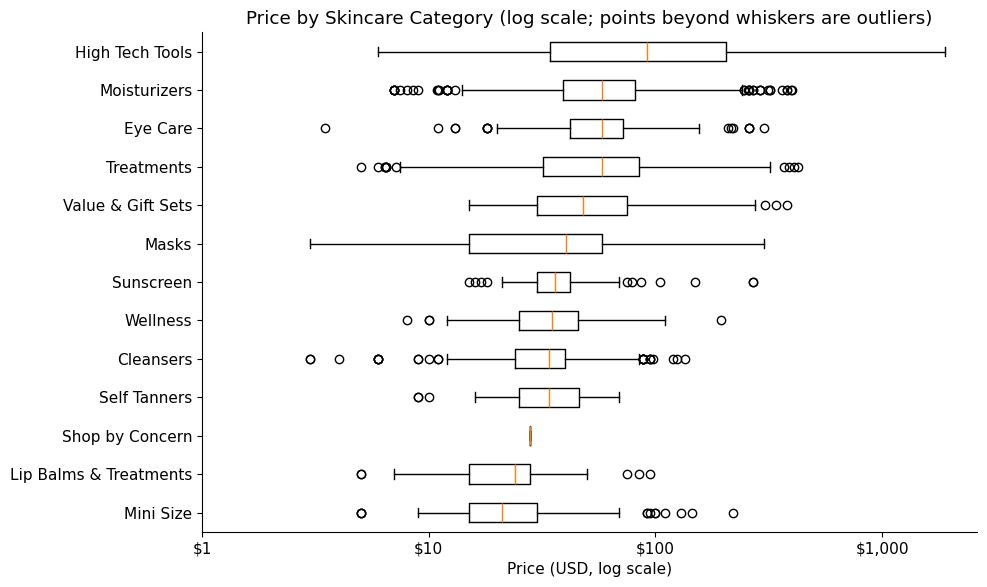

In [25]:
# Box plots: log price by category, sorted by median
order = skincare_products.groupby("secondary_category")["price_usd"].median().sort_values().index
data = [np.log10(skincare_products.loc[skincare_products["secondary_category"] == c, "price_usd"]) for c in order]
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(data, vert=False, showfliers=True)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)  # set labels separately: works on old and new matplotlib
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(["$1", "$10", "$100", "$1,000"])
ax.set_title("Price by Skincare Category (log scale; points beyond whiskers are outliers)")
ax.set_xlabel("Price (USD, log scale)")
plt.tight_layout()
plt.show()

- Prices are strongly right-skewed (skew 9.53, or 0.03 after a log transform), which is why the charts use a log scale
- **Expensive products are retained as plausible records.** The global IQR rule flags 170 products above 133 USD. Their prices fit their product types (LED masks and microcurrent devices up to 1,900 USD, luxury creams such as La Mer, multi-item value sets), no price is zero or negative, and the review files record the same prices as the catalog. We could not verify the prices independently, so we flag these products rather than delete them
- One global fence mixes very different categories: it flags 35 High Tech Tools but only 1 cleanser. The **within-category** rule flags 181 products that are expensive *for their own category* (for example 34 cleansers but only 3 High Tech Tools), which is how a category manager compares prices
- The products priced furthest above their own category are mostly La Mer items (6.9x to 10.5x the category median) and the 1,900 USD LED mask (20.7x). Several have very few reviews (the two Shiseido sunscreens have 2 each), so their ratings say little yet

**What we found: product assortment and pricing**

**Inventory and Marketing:**
Moisturizers, treatments and cleansers make up 56.9% of the skincare catalog (1,378 of 2,420 products), so they form the core of the assortment by product count; their share of sales is unknown. Smaller categories (self tanners, lip balms, wellness) have only 53-79 products each, so a single launch or delisting there changes the category noticeably. Increasing inventory and marketing in the core categories could drive sales, but we first need to check customer satisfaction (next sections).

**Pricing:**
Skincare prices range widely from 3 USD to 1,900 USD, but the median of 44 USD and mean of 61 USD show that most products sit in an accessible range. The price bands use right-closed boundaries: "$25 or less" includes 25.00 USD, "$25.01-50" covers prices above 25 USD up to and including 50 USD, and so on. The $25.01-50 band is the largest (904 products, 37%), while 260 products (11%) cost over 100 USD. The most expensive items are high-tech devices, which serve a different customer segment, so prices are best compared within categories.

**Brand Positioning:**
Premium brands like La Mer (4.5x its category median) and Dr. Barbara Sturm (3.7x) are priced far above their categories, yet their average ratings (4.15 and 4.01) are at or below the skincare average (4.23). The category manager should check whether demand or brand prestige justifies these premiums.

**Caveat:**
Product counts reflect catalog assortment, not actual sales or market share. Relative price does not adjust for package size or ingredients. These findings are directional and should be validated with sales data.

## Price, product ratings and review volume

Rated skincare products: 2351
Spearman price-rating correlation: 0.13


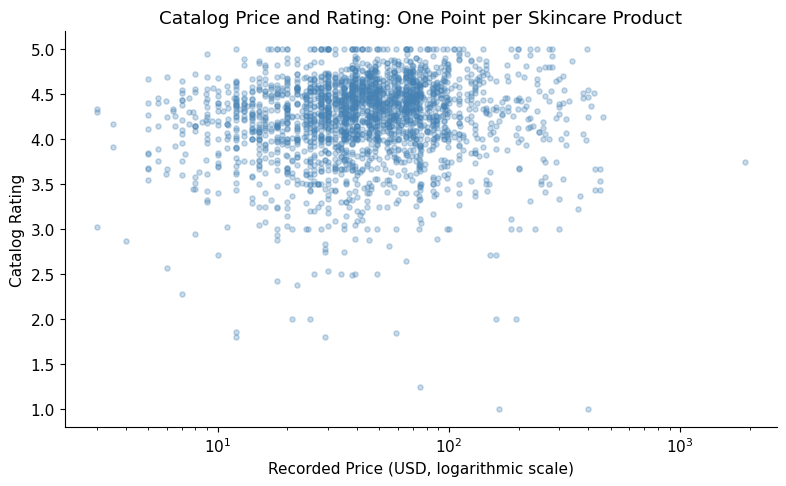

In [26]:
# One row per rated product
rated_products = skincare_products.dropna(subset=["price_usd", "rating"]).copy()
print("Rated skincare products:", len(rated_products))

# Spearman correlation compares rankings, so a few very high prices do not dominate it
print("Spearman price-rating correlation:", round(rated_products["price_usd"].corr(rated_products["rating"], method="spearman"), 3))

rated_products.plot.scatter(x="price_usd", y="rating", alpha=0.3, s=14, color="steelblue")
plt.title("Catalog Price and Rating: One Point per Skincare Product")
plt.xscale("log")
plt.xlabel("Recorded Price (USD, logarithmic scale)")
plt.ylabel("Catalog Rating")
plt.tight_layout()
plt.show()

In [27]:
# Does the relationship hold inside each category?
by_category = rated_products.groupby("secondary_category")[["price_usd", "rating"]].apply(
    lambda g: g["price_usd"].corr(g["rating"], method="spearman")
)
category_relationships = pd.DataFrame({
    "Rated products": rated_products.groupby("secondary_category").size(),
    "Spearman correlation": by_category
})
display(category_relationships.round(3))

# And among products with at least 20 catalog reviews?
enough_reviews = rated_products["reviews"] >= 20
print("Products with at least 20 reviews:", enough_reviews.sum())
print("Spearman correlation for them:", round(
    rated_products.loc[enough_reviews, "price_usd"].corr(rated_products.loc[enough_reviews, "rating"], method="spearman"), 3))

,Rated products,Spearman correlation
secondary_category,,
Cleansers,354,0.241
Eye Care,184,0.085
High Tech Tools,76,0.007
Lip Balms & Treatments,61,-0.037
Masks,165,0.148
Mini Size,110,-0.030
Moisturizers,538,0.138
Self Tanners,53,0.109
Shop by Concern,1,NaN


Products with at least 20 reviews: 1923
Spearman correlation for them: 0.156


In [28]:
# Ratings by how many reviews a product has
reviewed_products = rated_products.dropna(subset=["reviews"]).copy()
reviewed_products["review_count_band"] = pd.cut(
    reviewed_products["reviews"],
    bins=[0, 10, 100, 1000, np.inf],
    labels=["1-10", "11-100", "101-1,000", "Over 1,000"],
    include_lowest=True
)
reviewed_products.groupby("review_count_band", observed=True).agg(
    Products=("product_id", "size"),
    Mean_rating=("rating", "mean"),
    Rating_standard_deviation=("rating", "std")
).round(3)

,Products,Mean_rating,Rating_standard_deviation
review_count_band,,,
1-10,268,4.086,0.812
11-100,699,4.137,0.513
"101-1,000",1083,4.307,0.342
"Over 1,000",301,4.289,0.242


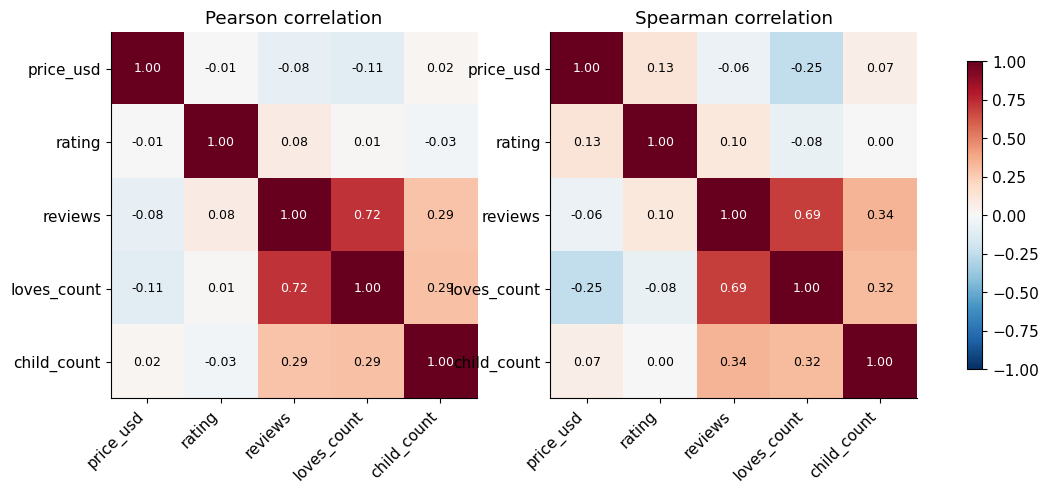

In [29]:
# Correlation heatmap
num_cols = [c for c in ["price_usd", "rating", "reviews", "loves_count", "child_count"] if c in skincare_products]
num = skincare_products[num_cols]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = num.corr(method=method)          # pairwise: each pair uses the rows where both exist
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(num_cols)))
    ax.set_xticklabels(num_cols, rotation=45, ha="right")
    ax.set_yticks(range(len(num_cols)))
    ax.set_yticklabels(num_cols)
    for i in range(len(num_cols)):
        for j in range(len(num_cols)):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(value) > 0.6 else "black")   # readable on dark cells
    ax.set_title(method.title() + " correlation")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

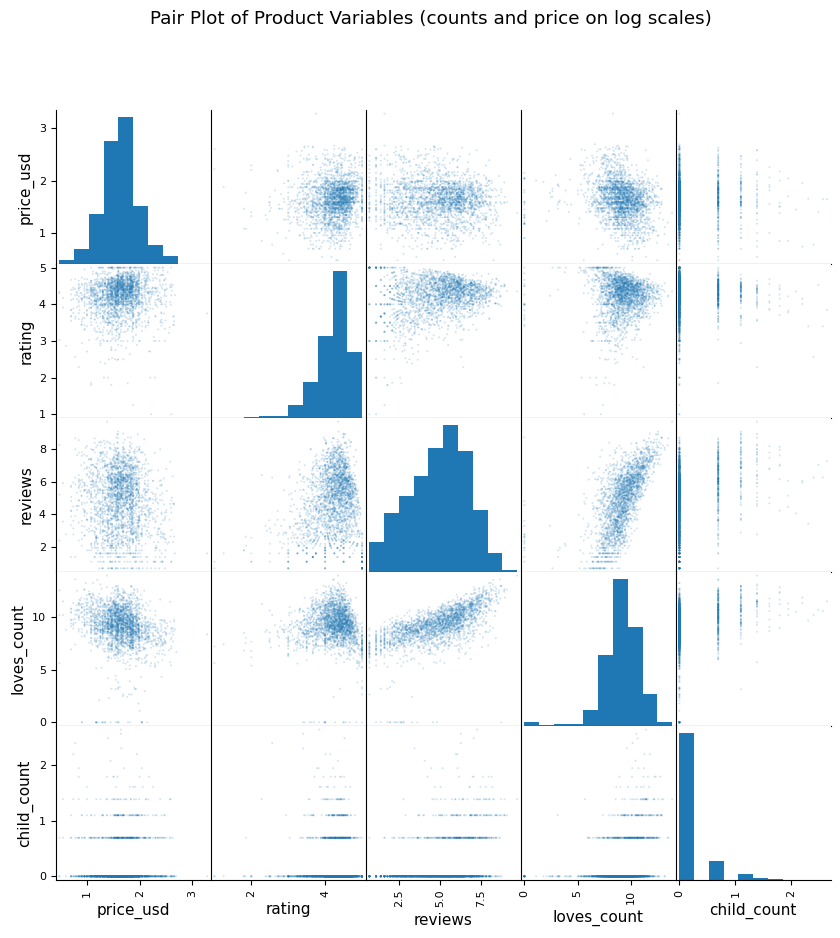

In [30]:
# Pair plot: every pair of numeric product variables, on log scales
log_num = pd.DataFrame({
    c: np.log10(num[c]) if c == "price_usd" else (np.log1p(num[c]) if c != "rating" else num[c])
    for c in num_cols
})
pd.plotting.scatter_matrix(log_num, figsize=(10, 10), alpha=0.2, s=8, diagonal="hist")
plt.suptitle("Pair Plot of Product Variables (counts and price on log scales)")
plt.show()

In [31]:
# Product flags (group-by): do new, exclusive, online-only or limited products differ?
flag_cols = [c for c in ["new", "sephora_exclusive", "online_only", "limited_edition", "out_of_stock"] if c in skincare_products]
flag_rows = []
for f in flag_cols:
    g = skincare_products.groupby(f).agg(Products=("product_id", "size"), Median_price=("price_usd", "median"),
                                         Mean_rating=("rating", "mean"))
    g.index = [f"{f} = {v}" for v in g.index]
    flag_rows.append(g)
pd.concat(flag_rows).round(2)

,Products,Median_price,Mean_rating
new = 0,2226,44.0,4.21
new = 1,194,45.0,4.50
sephora_exclusive = 0,1695,49.0,4.22
sephora_exclusive = 1,725,34.0,4.25
online_only = 0,1913,42.0,4.22
online_only = 1,507,48.0,4.27
limited_edition = 0,2315,44.0,4.23
limited_edition = 1,105,58.0,4.14
out_of_stock = 0,2288,44.0,4.23
out_of_stock = 1,132,34.0,4.14


- **Popularity measures move together:** catalog review count and loves count have the strongest relationship (Pearson 0.72, Spearman 0.69), and both rise with the number of product variants (child count, about 0.3)
- **Price says little about rating:** almost no linear relationship (Pearson -0.01) and only a weak rank relationship (Spearman 0.13). Higher-priced products tend to have somewhat fewer loves (Spearman -0.25)
- Pearson and Spearman disagree when a few extreme values dominate; Spearman is the better guide for skewed prices and counts. `df.corr()` uses pairwise deletion, so correlations involving `rating` use only rated products. The covariance matrix is in Appendix E
- **For the category manager:** loves and review counts both measure platform engagement; whether they track demand would need validation against sales data. Price is not a signal of customer satisfaction

**What we found — Price and Ratings**

**Marketing decisions:**
Price alone is not a reliable indicator of product popularity 
or customer satisfaction. These results suggest that ratings can 
help identify products for further review, but promotion decisions 
should also be evaluated against sales, margin, returns and category 
strategy. Even within the same category, price-rating correlation is 
weak (ranging from -0.04 for lip balms to 0.24 for cleansers).

**Using ratings reliably:**
Ratings for products with few reviews may not reflect true 
customer sentiment - standard deviation is 0.81 for products 
with 1-10 reviews compared to 0.24 for products with over 
1,000 reviews. Sephora should be extra careful when using 
ratings from low-review products to make inventory or 
marketing decisions, and always display review counts 
alongside ratings.

**Caveat:**
These findings show a correlation between price and ratings 
but do not prove product effectiveness or explain what 
causes a customer to rate a product highly. Further analysis 
of customer reviews is needed before drawing conclusions.

**Price bands:**
Average ratings rise across the first three price bands (4.12, 4.25, 4.30) and dip above 100 USD (4.20). Mid-priced products (50.01-100 USD) earn the best ratings, so premium pricing above 100 USD should be justified by something other than expected satisfaction, such as brand prestige or margin.

## Customer review patterns

,Rating
Mean individual review rating,4.299
Mean of each reviewed product's mean rating,4.227
Mean available catalog product rating,4.229


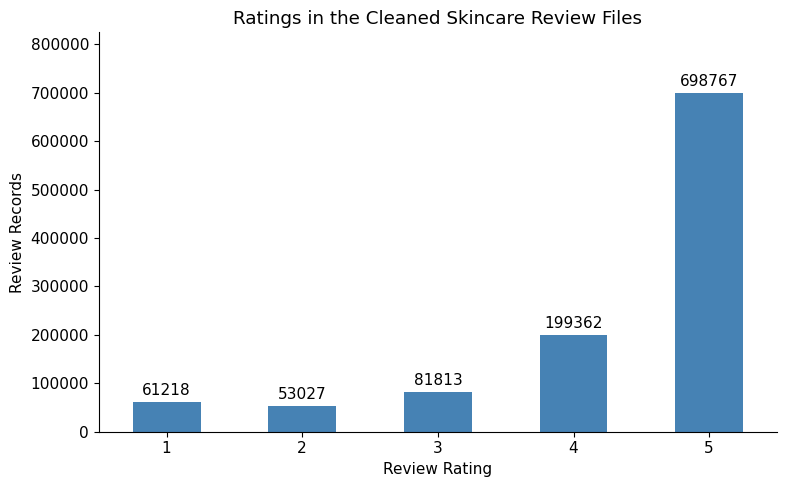

In [32]:
# Three different "average ratings"
product_review_means = skincare_reviews.groupby("product_id")["review_rating"].mean()
weighting_summary = pd.Series({
    "Mean individual review rating": skincare_reviews["review_rating"].mean(),
    "Mean of each reviewed product's mean rating": product_review_means.mean(),
    "Mean available catalog product rating": rated_products["rating"].mean()
}, name="Rating")
display(weighting_summary.round(3).to_frame())

rating_counts = skincare_reviews["review_rating"].value_counts().sort_index()
rating_counts.index = rating_counts.index.astype(int)
ax = rating_counts.plot.bar(color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.ylim(0, rating_counts.max() * 1.18)
plt.title("Ratings in the Cleaned Skincare Review Files")
plt.xlabel("Review Rating")
plt.ylabel("Review Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
# Recommendation rate among known responses, with the denominator shown
recommendation_summary = skincare_reviews.groupby("secondary_category").agg(
    Review_records=("review_rating", "size"),
    Known_recommendations=("is_recommended", "count"),
    Recommendation_rate=("is_recommended", "mean"),
    Mean_review_rating=("review_rating", "mean")
)
recommendation_summary["Response coverage (%)"] = (
    recommendation_summary["Known_recommendations"] / recommendation_summary["Review_records"] * 100
)
recommendation_summary["Recommendation_rate"] *= 100
recommendation_summary.round(2)

,Review_records,Known_recommendations,Recommendation_rate,Mean_review_rating,Response coverage (%)
secondary_category,,,,,
Cleansers,200565,157437,84.43,4.34,78.50
Eye Care,74991,66180,82.63,4.18,88.25
High Tech Tools,5925,5591,81.17,4.18,94.36
Lip Balms & Treatments,61660,45674,81.10,4.33,74.07
Masks,70527,56754,85.16,4.34,80.47
Mini Size,85489,77073,82.77,4.29,90.16
Moisturizers,297343,246515,84.61,4.32,82.91
Self Tanners,11942,11601,78.89,4.08,97.14
Shop by Concern,15,15,66.67,4.27,100.00


In [34]:
# Compare skin types and keep the Unknown group instead of guessing
skin_type_summary = skincare_reviews.groupby("skin_type_group").agg(
    Review_records=("review_rating", "size"),
    Distinct_products=("product_id", "nunique"),
    Mean_rating=("review_rating", "mean"),
    Known_recommendations=("is_recommended", "count"),
    Recommendation_rate=("is_recommended", "mean")
)
skin_type_summary["Recommendation_rate"] *= 100
skin_type_summary["Response coverage (%)"] = (
    skin_type_summary["Known_recommendations"] / skin_type_summary["Review_records"] * 100
)
display(skin_type_summary.round(2))

# Each skin type may review a different mix of products
skin_category_mix = pd.crosstab(
    skincare_reviews["skin_type_group"], skincare_reviews["secondary_category"], normalize="index"
) * 100
skin_category_mix.round(1)

,Review_records,Distinct_products,Mean_rating,Known_recommendations,Recommendation_rate,Response coverage (%)
skin_type_group,,,,,,
Unknown,111449,1816,4.31,19067,81.80,17.11
combination,544447,2320,4.31,501314,84.48,92.08
dry,185913,2251,4.29,174169,83.63,93.68
normal,131897,2192,4.28,122168,83.43,92.62
oily,120481,2117,4.27,109596,83.38,90.97


secondary_category,Cleansers,Eye Care,High Tech Tools,Lip Balms & Treatments,Masks,Mini Size,Moisturizers,Self Tanners,Shop by Concern,Sunscreen,Treatments,Value & Gift Sets,Wellness
skin_type_group,,,,,,,,,,,,,
Unknown,20.6,4.9,0.4,8.4,12.3,4.6,30.5,0.4,0.0,1.5,14.2,1.3,0.8
combination,18.4,7.1,0.5,5.1,5.8,8.2,26.4,1.1,0.0,3.9,21.2,1.1,1.0
dry,16.4,7.0,0.6,5.4,5.8,8.0,29.7,1.2,0.0,4.1,20.0,1.0,0.9
normal,16.6,8.0,0.6,6.0,5.6,7.9,26.3,1.7,0.0,4.5,20.8,1.1,1.0
oily,20.6,6.1,0.5,5.3,5.7,8.7,24.4,1.0,0.0,3.8,21.7,1.1,1.0


**What we found: customer reviews and satisfaction**

**Overall Satisfaction:**
The average review rating is 4.299 and 84.0% of known responses recommend the product. Giving each reviewed product equal weight lowers the average to 4.227, because popular products with many reviews pull the first number up.

**Caution on Ratings:**
63.9% of reviews are five-star. Customers choose whether to write a review, so very satisfied (and very unhappy) customers may be over-represented. The recommendation question is skipped at similar rates across star ratings (12.7% to 16.0%), but this cannot rule out that the skipped answers differ. Ratings are best used to compare products with each other rather than as an absolute satisfaction score.

**Skin Types:**
Ratings are similar across recorded skin types (4.27 to 4.31), and recommendation rates differ by about one percentage point (83.4% to 84.5%), each based on 91% to 94% response coverage. Reviewers who left skin type blank answered the recommendation question only 17.1% of the time, so the two questions tend to be skipped together and the Unknown group's 81.8% rate rests on few responses. Aggregate skin-type averages cannot estimate how well a skin-type campaign would work, and each skin type reviews a different product mix, so comparisons should be made within categories.

**Caveat:**
Review counts reflect platform activity, not actual sales. Data ends March 2023, so recent trends and product launches are not captured.

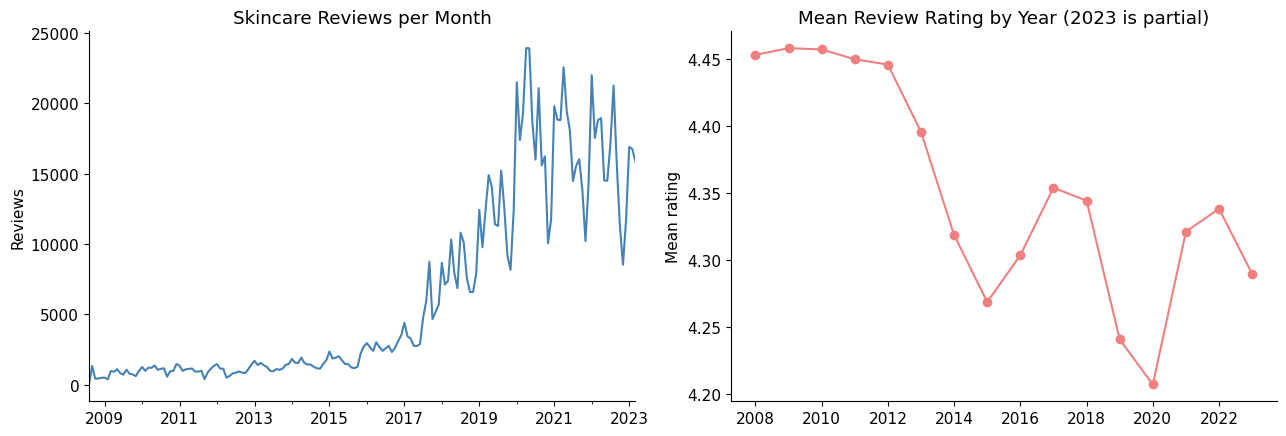

,Reviews,Mean_rating,Recommendation_rate
submission_time,,,
2008,2761,4.45,NaN
2009,9709,4.46,NaN
2010,13477,4.46,NaN
2011,12417,4.45,NaN
2012,11799,4.45,NaN
2013,15559,4.40,NaN
2014,18181,4.32,NaN
2015,21590,4.27,NaN
2016,33137,4.30,NaN


In [35]:
# Time series
monthly = skincare_reviews.groupby(skincare_reviews["submission_time"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()

yearly = skincare_reviews.groupby(skincare_reviews["submission_time"].dt.year).agg(
    Reviews=("review_rating", "size"),
    Mean_rating=("review_rating", "mean"),
    Recommendation_rate=("is_recommended", "mean"),
)
yearly["Recommendation_rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
monthly.plot(ax=axes[0], color="steelblue")
axes[0].set_title("Skincare Reviews per Month")
axes[0].set_xlabel("")
axes[0].set_ylabel("Reviews")
yearly["Mean_rating"].plot(ax=axes[1], marker="o", color="lightcoral")
axes[1].set_title("Mean Review Rating by Year (2023 is partial)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean rating")
plt.tight_layout()
plt.show()
yearly.round(2)

- Review volume grew from 2,761 reviews in 2008 to a peak of 215,419 in 2020, then held near 200,000 a year in 2021-2022. 2023 covers only January 1 to March 21 (49,531 reviews)
- The mean rating fell from about 4.45 (2008-2012) to a low of 4.21 in 2020, then recovered to 4.34 in 2022. The recommendation question appears only from 2017 onward, with rates between 81.9% (2020) and 87.2% (2017)
- Early years have few reviews, so their averages are noisy. Volume shows activity, not sales
- **For the category manager:** the 2019-2020 dip came during the fastest growth in reviewer numbers, so a broader reviewer base may explain part of it. Track satisfaction over time for the same products rather than for the whole category

## Labels, ingredients and feature engineering

In [36]:
# "highlights" is stored as text that looks like a list, e.g. "['Vegan', 'Hydrating']".
# ast.literal_eval turns that text into a real Python list.
def parse_labels(value):
    """Return a list of labels, or an empty list when the value is missing or unreadable."""
    if pd.isna(value):
        return []
    try:
        labels = ast.literal_eval(value)
        return labels if isinstance(labels, list) else []
    except (ValueError, SyntaxError):
        return []

skincare_products["highlight_list"] = skincare_products["highlights"].apply(parse_labels)
skincare_labels = skincare_products[["product_id", "highlight_list"]].explode("highlight_list").dropna()
skincare_labels["highlight_list"] = skincare_labels["highlight_list"].str.strip()
skincare_labels = skincare_labels[skincare_labels["highlight_list"] != ""].drop_duplicates()
display(skincare_labels["highlight_list"].value_counts().head(15).to_frame("Products"))

print("Skincare products missing ingredients:", skincare_products["ingredients"].isna().sum())
print("Skincare products missing size:", skincare_products["size"].isna().sum())

,Products
highlight_list,
Good for: Dullness/Uneven Texture,744
Clean at Sephora,741
Vegan,689
Good for: Dryness,603
Cruelty-Free,579
Good for: Anti-Aging,574
Hydrating,432
Without Parabens,419
Good for: Loss of firmness,393


Skincare products missing ingredients: 134
Skincare products missing size: 365


- The most common skincare labels describe concerns ("Good for: Dullness/Uneven Texture", 744 products) and values ("Clean at Sephora", 741; "Vegan", 689)
- Highlights are labels recorded by the retailer, not independently checked claims. A missing label does not mean a product lacks that feature
- 134 skincare products have no ingredient list and 365 have no size. Ingredients and sizes need more standardization before comparing formulas or price per milliliter
- **For the category manager:** the next cell turns the most common labels into 0/1 features to show whether claims such as "Clean" or "Vegan" go with different pricing or ratings, which can inform which claims to test in merchandising

In [37]:
# Feature engineering: 0/1 indicator (dummy) columns for the eight most common highlight labels
# Only products with at least one usable recorded highlight are compared. For the others we do not know
# which labels apply, so counting them as "without the label" would mix unknown labels with absent ones
top_labels = list(skincare_labels["highlight_list"].value_counts().head(8).index)
# explode() repeats the row index, so pass plain arrays to crosstab
label_dummies = pd.crosstab(skincare_labels["product_id"].to_numpy(), skincare_labels["highlight_list"].to_numpy(),
                            rownames=["product_id"], colnames=[None])[top_labels].clip(upper=1)

labelled_products = skincare_products[["product_id", "price_usd", "relative_price", "rating"]].merge(
    label_dummies.reset_index(), on="product_id", how="inner"
)
print("Skincare products with usable recorded highlights:", len(labelled_products))
print("Skincare products with no usable highlights (excluded as unknown):", len(skincare_products) - len(labelled_products))

label_comparison = pd.DataFrame([
    {
        "Label": label,
        "Products: label recorded": labelled_products[label].sum(),
        "Products: other labels recorded": (labelled_products[label] == 0).sum(),
        "Median relative price (label recorded)": labelled_products.loc[labelled_products[label] == 1, "relative_price"].median(),
        "Median relative price (other labels)": labelled_products.loc[labelled_products[label] == 0, "relative_price"].median(),
        "Mean rating (label recorded)": labelled_products.loc[labelled_products[label] == 1, "rating"].mean(),
        "Mean rating (other labels)": labelled_products.loc[labelled_products[label] == 0, "rating"].mean(),
    }
    for label in top_labels
]).set_index("Label")
label_comparison.round(2)

Skincare products with usable recorded highlights: 2003
Skincare products with no usable highlights (excluded as unknown): 417


,Products: label recorded,Products: other labels recorded,Median relative price (label recorded),Median relative price (other labels),Mean rating (label recorded),Mean rating (other labels)
Label,,,,,,
Good for: Dullness/Uneven Texture,744,1259,1.12,0.93,4.33,4.23
Clean at Sephora,741,1262,0.88,1.04,4.22,4.29
Vegan,689,1314,0.88,1.04,4.25,4.28
Good for: Dryness,603,1400,1.00,1.00,4.30,4.25
Cruelty-Free,579,1424,1.00,1.00,4.24,4.28
Good for: Anti-Aging,574,1429,1.24,0.88,4.27,4.26
Hydrating,432,1571,0.95,1.00,4.29,4.26
Without Parabens,419,1584,1.04,0.99,4.26,4.27


- **How to read the table:** among products with at least one usable recorded highlight, each row compares products where the label is recorded with products that have other labels recorded but not this one. A relative price of 1.0 means the product costs the median for its category
- Products with no usable highlights are excluded, because we cannot tell whether they lack a label or simply have none recorded
- A label that goes with a higher rating at a similar or lower relative price is a candidate to test in marketing; a label that goes with a premium price but no rating advantage deserves a closer look
- These differences are descriptive, not causal: labels are linked to brand and category (for example, some brands label every product "Clean")

### Feature scaling
Price, rating, review count and loves are measured in very different units (dollars, 1-5 stars, up to 21,281 reviews and millions of loves). **Min-max scaling** maps each feature to a common 0-1 range so they can be compared and combined; without it, the feature with the largest numbers would dominate any combined score or distance-based model. We log-transform the skewed price and count features first, so a few extreme products do not squeeze every other product close to zero.

We then use the scaled features for an **exploratory screening index**: a weighted average of scaled rating, scaled popularity (loves) and inverted scaled relative price, for products with at least 20 catalog reviews. The equal weights are an arbitrary starting point: putting features on the same scale does not make them equally important, and the index does not measure consumer value. The second cell checks whether the top-ranked products change under alternative weights.

In [38]:
# Min-max scaling: put product features on a common 0-1 scale
scaling_inputs = pd.DataFrame({
    "log_price": np.log10(skincare_products["price_usd"]),
    "log_relative_price": np.log10(skincare_products["relative_price"]),
    "rating": skincare_products["rating"],
    "log_reviews": np.log1p(skincare_products["reviews"]),
    "log_loves": np.log1p(skincare_products["loves_count"]),
}).dropna()

scaler = MinMaxScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(scaling_inputs), columns=scaling_inputs.columns, index=scaling_inputs.index
)
display(pd.concat({
    "Before scaling": scaling_inputs.describe().loc[["min", "mean", "max"]],
    "After min-max scaling": scaled_features.describe().loc[["min", "mean", "max"]]
}).round(2))

# Exploratory screening index with equal (arbitrary) weights: rating, popularity, low relative price
def screening_score(features, weights):
    w_rating, w_loves, w_price = weights
    return (w_rating * features["rating"] + w_loves * features["log_loves"]
            + w_price * (1 - features["log_relative_price"]))

eligible = scaled_features.index.intersection(skincare_products.index[skincare_products["reviews"] >= 20])
scaled_features["screening_index"] = screening_score(scaled_features, (1 / 3, 1 / 3, 1 / 3))
screened_products = skincare_products.loc[eligible].join(scaled_features["screening_index"])
screened_products.nlargest(10, "screening_index")[
    ["product_name", "brand_name", "secondary_category", "price_usd", "rating", "reviews", "screening_index"]
].round(2)

log_price  log_relative_price  rating  \
Before scaling        min        0.48               -1.22    1.00   
                      mean       1.63               -0.03    4.23   
                      max        3.28                1.31    5.00   
After min-max scaling min        0.00                0.00    0.00   
                      mean       0.41                0.47    0.81   
                      max        1.00                1.00    1.00   

                            log_reviews  log_loves  
Before scaling        min          0.69       0.00  
                      mean         4.87       9.23  
                      max          9.69      13.89  
After min-max scaling min          0.00       0.00  
                      mean         0.46       0.66  
                      max          1.00       1.00

,product_name,brand_name,secondary_category,price_usd,rating,reviews,screening_index
7648,Niacinamide 10% + Zinc 1% Oil Control Serum,The Ordinary,Treatments,6.0,4.24,5778.0,0.90
7652,AHA 30% + BHA 2% Exfoliating Peeling Solution,The Ordinary,Treatments,9.5,4.57,3242.0,0.89
6439,Cleansing & Exfoliating Wipes,SEPHORA COLLECTION,Cleansers,3.0,4.34,3837.0,0.89
7659,Lactic Acid 10% + HA 2% Exfoliating Serum,The Ordinary,Treatments,8.9,4.50,1289.0,0.87
6662,Facial Cleansing Tool,SEPHORA COLLECTION,High Tech Tools,8.0,4.73,100.0,0.86
7655,Natural Moisturizing Factors + HA,The Ordinary,Treatments,6.5,4.15,2052.0,0.86
7671,Mandelic Acid 10% + HA,The Ordinary,Treatments,7.5,4.46,431.0,0.86
7676,100% Plant-Derived Hemi-Squalane,The Ordinary,Treatments,5.0,4.40,294.0,0.85
6556,Clean Eye Mask,SEPHORA COLLECTION,Masks,3.5,4.17,371.0,0.85
7657,100% Organic Cold-Pressed Rose Hip Seed Oil,The Ordinary,Moisturizers,10.9,4.40,1620.0,0.85


In [39]:
# Sensitivity check: do the top-ranked products change when the arbitrary weights change?
weight_sets = {
    "Equal (1/3 each)": (1 / 3, 1 / 3, 1 / 3),
    "Rating-heavy (50/25/25)": (0.50, 0.25, 0.25),
    "Popularity-heavy (25/50/25)": (0.25, 0.50, 0.25),
    "Price-heavy (25/25/50)": (0.25, 0.25, 0.50),
}
index_scores = pd.DataFrame({name: screening_score(scaled_features.loc[eligible], w) for name, w in weight_sets.items()})
equal_top20 = set(index_scores["Equal (1/3 each)"].nlargest(20).index)
pd.DataFrame({
    "Top-20 products shared with equal weights": {name: len(equal_top20 & set(index_scores[name].nlargest(20).index))
                                                  for name in weight_sets},
    "Rank correlation with equal weights": index_scores.corr(method="spearman")["Equal (1/3 each)"],
}).round(3)

,Top-20 products shared with equal weights,Rank correlation with equal weights
Equal (1/3 each),20,1.000
Rating-heavy (50/25/25),15,0.924
Popularity-heavy (25/50/25),16,0.957
Price-heavy (25/25/50),14,0.952


- After scaling, every feature runs from 0 to 1, but equal scaling and equal weights do not establish equal importance or consumer value
- With equal weights, the top 10 are all low-priced products from two value brands (The Ordinary and SEPHORA COLLECTION, all 11 USD or less), which shows how strongly the relative-price component pulls the score
- The sensitivity table shows how many of the top 20 products stay in the top 20 under other weightings, and how closely the full rankings agree. Products that stay near the top under every weighting are the most robust shortlist
- **For the category manager:** use the index only to shortlist products for a closer look, alongside sales, margin and category fit. It should not decide promotions on its own

## Review text analysis
We flag reviews that mention four themes a category manager cares about: hydration (a core skincare benefit), irritation and breakouts (quality complaints) and price (value for money). We then compare how often each appears in low-, middle- and high-rated reviews. An exploratory topic model is in Appendix C.

Usable review texts: 1092743


,Reviews with text
rating_group,
High (4-5),896943
Low (1-2),114051
Middle (3),81749


,hydration_mention,irritation_mention,breakout_mention,price_mention
rating_group,,,,
Low (1-2),20.63,7.91,17.86,13.60
Middle (3),31.93,6.98,12.83,18.15
High (4-5),35.56,7.16,13.78,11.33


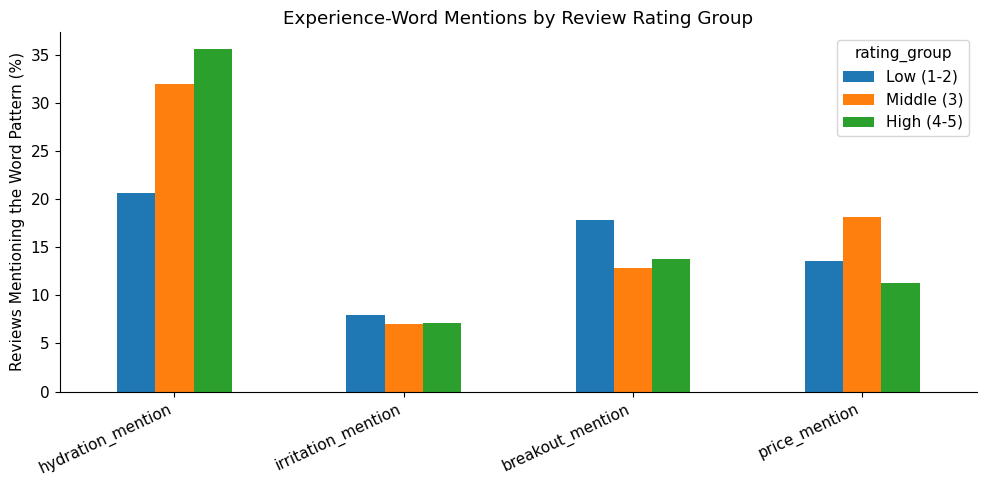

hydration_mention: 35.6% of high-rated, 31.9% of 3-star and 20.6% of low-rated reviews
irritation_mention: 7.2% of high-rated, 7.0% of 3-star and 7.9% of low-rated reviews
breakout_mention: 13.8% of high-rated, 12.8% of 3-star and 17.9% of low-rated reviews
price_mention: 11.3% of high-rated, 18.2% of 3-star and 13.6% of low-rated reviews


In [40]:
# Keep only reviews with text, then clean it: lowercase, remove HTML tags, tidy spaces
text_reviews = skincare_reviews.dropna(subset=["review_text"])[
    ["product_id", "review_rating", "review_text", "secondary_category"]
].copy()
text_reviews["clean_text"] = (
    text_reviews["review_text"].str.lower()
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
text_reviews = text_reviews[text_reviews["clean_text"] != ""].copy()
print("Usable review texts:", len(text_reviews))

# Flag reviews that contain selected word patterns (mentions, not verified effects)
text_reviews["hydration_mention"] = text_reviews["clean_text"].str.contains(r"\bhydrat\w*|\bmoistur\w*", regex=True)
text_reviews["irritation_mention"] = text_reviews["clean_text"].str.contains(r"\birritat\w*|\bburn(?:s|ing|ed)?\b", regex=True)
text_reviews["breakout_mention"] = text_reviews["clean_text"].str.contains(r"\bbreak[ -]?outs?\b|\bacne\b", regex=True)
text_reviews["price_mention"] = text_reviews["clean_text"].str.contains(r"\bexpensive\b|\bprice\b|\bworth\b", regex=True)

text_reviews["rating_group"] = pd.cut(
    text_reviews["review_rating"], bins=[0, 2, 3, 5], labels=["Low (1-2)", "Middle (3)", "High (4-5)"]
)
mention_columns = ["hydration_mention", "irritation_mention", "breakout_mention", "price_mention"]
mention_rates = text_reviews.groupby("rating_group", observed=True)[mention_columns].mean() * 100
display(text_reviews["rating_group"].value_counts().to_frame("Reviews with text"))
display(mention_rates.round(2))

mention_rates.T.plot.bar(figsize=(10, 5))
plt.title("Experience-Word Mentions by Review Rating Group")
plt.ylabel("Reviews Mentioning the Word Pattern (%)")
plt.xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Read the table in words (the numbers are computed from the data above)
for col in mention_columns:
    print(f"{col}: {mention_rates.loc['High (4-5)', col]:.1f}% of high-rated, "
          f"{mention_rates.loc['Middle (3)', col]:.1f}% of 3-star and "
          f"{mention_rates.loc['Low (1-2)', col]:.1f}% of low-rated reviews")

In [41]:
# A keyword is not proof: read examples, because negation and context can reverse the meaning
def show_review_examples(frame, title, n=3, max_chars=400):
    # Print a few reviews in full sentences, wrapped to a readable width
    print(title)
    for _, row in frame.sample(min(n, len(frame)), random_state=42).iterrows():
        review = row["review_text"]
        if len(review) > max_chars:
            review = review[:max_chars].rsplit(" ", 1)[0] + " ..."
        print(f"\n  [{int(row['review_rating'])} stars]")
        print(textwrap.fill(review, width=100, initial_indent="  ", subsequent_indent="  "))
    print("\n" + "-" * 100 + "\n")

irritation_reviews = text_reviews[text_reviews["irritation_mention"]]
show_review_examples(irritation_reviews[irritation_reviews["review_rating"] <= 2], "Low-rated reviews that mention irritation")
show_review_examples(irritation_reviews[irritation_reviews["review_rating"] >= 4], "High-rated reviews that mention irritation")

Low-rated reviews that mention irritation

  [2 stars]
  Honestly did not notice a difference in my skin after using this peel. It made my skin feel sticky
  and uncomfortable after using. Also, I am used to using chemical masks/peels and this really
  irritated my skin. Would not purchase. I received this product complimentary for testing purposes.

  [1 stars]
  I got this as a sample as I purchased some Caudalie stuff for my mum who loves it, and I really
  wanted to like it. However I don’t know if I’m allergic to it or just have bad luck, but as soon
  as I put this on my skin it felt like it was burning. I tried to wipe it off, and I didn’t use it
  again, unfortunately just that quick use was enough to result in some of the driest skin I have
  ever ...

  [1 stars]
  So I’m not exactly sure what happened but my skin got irritated as I was doing my skincare. The
  lower part of my face by my chin got red and welted. It actually feels numb! I put the peptides on
  at the very end

**What we found: customer review text**

**What customers mention:**
Hydration words appear in 35.6% of high-rated reviews against 20.6% of low-rated ones, so hydration goes with satisfied customers. Breakout and acne words are the clearest negative signal (17.9% of low-rated against 13.8% of high-rated reviews). Price words are most common in 3-star reviews (18.2%), which suggests value-for-money doubts are common in middling reviews. Sephora could test highlighting hydration benefits in product descriptions and review pricing for products with many 3-star price comments.

**Using keyword analysis carefully:**
Irritation mentions are almost flat across ratings (7.0% to 7.9%) because phrases such as "bland enough to not irritate" also match the pattern, as the high-rated examples above show. Sephora should always read actual review examples before acting on keyword findings. These are associations in the text, not proof of what causes a rating.

**For the category manager:**
Breakout complaints and value-for-money comments are the two themes most linked to lower ratings. Whether tracking their share for each product gives an earlier warning than the average rating should be tested with dated, product-level comparisons.

**Caveat:**
The keyword analysis uses all 1,092,743 usable review texts, but simple patterns cannot handle negation. A next step is to handle negation, remove very common words and combine word forms (lemmatization).

## Main Findings and Next Steps

### Key Findings for the Skincare Category Manager (Midterm Checkpoint)

| Finding | Evidence | What it means for the category manager |
|---|---|---|
| The data supports the analysis | Prices complete, no invalid values, 224 duplicates removed, 97% of skincare products reviewed | Complete fields support the analysis but do not establish unbiased ratings, because reviewers self-select |
| The assortment is concentrated | Moisturizers, treatments and cleansers are 56.9% of products (1,378 of 2,420); $25.01-100 holds 67% | Niche categories are thin, so each launch or delisting there matters; their sales importance is unknown |
| Price does not predict ratings | Spearman 0.13; mean ratings peak at $50.01-100 (4.30) and dip above $100 (4.20) | Premium pricing needs a justification other than expected ratings |
| Some premium brands are priced far above their category | La Mer 4.5x and Dr. Barbara Sturm 3.7x the category median, with ratings of 4.15 and 4.01 | Review whether demand justifies these premiums, using sales data |
| Ratings from few reviews are noisy | Rating standard deviation 0.81 for 1-10 reviews against 0.24 above 1,000 | Set a minimum review count (e.g., 20) before ranking, promoting or delisting on ratings |
| Breakouts and price comments go with lower ratings | Breakout words 17.9% of low-rated vs 13.8% of high-rated; price words peak in 3-star reviews (18.2%) | Test whether tracking these themes per product gives earlier warning, using dated product-level comparisons |
| Recommendation gaps vary across observed groups | Missing 3% (self tanners) to 26% (lip balms) by category; 12.7%-16.0% across star ratings | Report coverage for each category; the comparisons cannot tell MAR from MNAR |
| The recommendation rate is sensitive to assumptions | 84.0% among known responses; full range 71.1%-86.5% if all missing answers were "no" or "yes"; 76.3%-84.0% if non-responders are up to 50 points less positive | Present the known-response rate with both ranges, kept separate |
| Skin-type averages differ little | Recommendation rates 83.4%-84.5% across recorded skin types | Aggregate skin-type averages cannot estimate campaign effectiveness |

### Business Recommendations (Based on Current Findings)
- Use **ratings and review counts together**, with a minimum review count, when comparing products
- Use the **exploratory screening index** only to shortlist products for a closer look, alongside sales, margin and category fit, not to choose promotions on its own
- **Review premium items that underperform**: products priced far above their category with average or below-average ratings
- **Investigate why recommendation responses are missing** (for example, where in the review form they are skipped) before changing the form

### Limitations
- **Historical snapshot:** reviews end March 21, 2023, and prices are not current
- **No sales data:** reviews and loves show platform engagement, not units sold, revenue, margin or returns
- **Self-selected reviewers:** the data has no verified-purchase or free-sample flag, so incentivized reviews may raise ratings
- **Missingness mechanism unknown:** the data cannot distinguish MAR from MNAR, so results depend on assumptions about missing answers
- **Simple text methods:** keyword matching misses negation, and the topic model is exploratory
- **Descriptive, not causal:** labels, prices and ratings are linked to brand and category, so differences do not prove cause and effect
- **Prices of expensive items are plausible but not independently verified,** and sizes are not standardized, so price per ounce cannot yet be compared

### What We Will Do Next (with Additional Data)
- **Sephora sales, margin, inventory and returns data:** test whether ratings, loves and review counts track demand, and weight findings by revenue
- **Current and competitor prices** (Sephora site, Ulta Beauty, Amazon): check whether premium pricing is competitive today
- **Google Trends search interest** for skincare concerns and ingredients (for example "retinol" or "niacinamide"), merged by month: compare search trends with the assortment
- **Ingredient databases** (for example the EU CosIng database): link breakout and irritation complaints to specific ingredients
- **Verified-purchase and incentivized-review flags:** remove biased reviews before measuring satisfaction
- **Analysis:** deep dives by category, brand comparisons within categories, sentiment analysis with negation handling, and dated product-level tests of whether complaint themes predict later rating changes

## Appendix: supporting demonstrations
These cells show techniques that support the main analysis but are not needed for its conclusions: (A) a tidy long table, (B) one-hot encoding, (C) an exploratory topic model, (D) imputation demonstrations and (E) the covariance matrix.

### A. Tidy (long) version of the brand mix table
The `brand_mix` crosstab stores categories in its column headers. `melt` turns it into one row per brand and category.

In [42]:
brand_mix_long = brand_mix.reset_index().melt(id_vars="brand_name", var_name="Category", value_name="Share (%)")
brand_mix_long.sort_values("Share (%)", ascending=False).head(10).round(1)

,brand_name,Category,Share (%)
47,Peter Thomas Roth,Treatments,31.0
34,Shiseido,Moisturizers,28.6
30,CLINIQUE,Moisturizers,27.8
31,Kiehl's Since 1851,Moisturizers,26.4
0,CLINIQUE,Cleansers,25.6
44,Shiseido,Sunscreen,23.2
23,SEPHORA COLLECTION,Masks,21.9
1,Kiehl's Since 1851,Cleansers,20.8
46,Kiehl's Since 1851,Treatments,18.9
48,SEPHORA COLLECTION,Treatments,18.8


### B. One-hot encoding and dummy variables for skin type
- **Nominal vs ordinal:** skin type has no order (nominal), so it becomes indicator columns. Review rating has an order (1 < 2 < ... < 5, ordinal), so it stays a number
- **OHE vs dummies:** the first table keeps one column per skin type (OHE). The second drops the first category (alphabetically "Unknown"), which becomes the baseline when the columns are used in a regression. These columns would be inputs for a future model of ratings by skin type

In [43]:
# One hot encoding (OHE): one 0/1 column for every skin type
skin_type_ohe = pd.get_dummies(skincare_reviews[["skin_type_group"]], prefix="skin_type", dtype=int)
display(skin_type_ohe.head())

# Dummy variables: the same code with drop_first=True (one column fewer)
skin_type_dummies = pd.get_dummies(skincare_reviews[["skin_type_group"]], prefix="skin_type", drop_first=True, dtype=int)
skin_type_dummies.head()

,skin_type_Unknown,skin_type_combination,skin_type_dry,skin_type_normal,skin_type_oily
0,0,0,1,0,0
1,1,0,0,0,0
2,0,0,1,0,0
3,0,1,0,0,0
4,0,1,0,0,0


,skin_type_combination,skin_type_dry,skin_type_normal,skin_type_oily
0,0,1,0,0
1,0,0,0,0
2,0,1,0,0
3,1,0,0,0
4,1,0,0,0


### C. Exploratory topic model (LDA)
LDA groups words that tend to appear together. We fit five topics on a repeatable sample of 20,000 reviews to keep the runtime short.

In [45]:
# A reproducible 20,000-review sample keeps the runtime short
text_sample = text_reviews.sample(n=min(20000, len(text_reviews)), random_state=42)
# keep only words with 3+ letters, so fragments such as "ve" (from "I've") are dropped
word_pattern = r"(?u)\b[a-zA-Z]{3,}\b"

# Topic modeling with LDA. LDA is fitted to word counts, so we use CountVectorizer here
# (raw counts, not TF-IDF, are the standard input for LDA).
topic_vectorizer = CountVectorizer(stop_words="english", min_df=20, max_df=0.8,
                                   max_features=2000, token_pattern=word_pattern)
topic_matrix = topic_vectorizer.fit_transform(text_sample["clean_text"])

n_topics = 5          # try other numbers and compare the results
lda = LatentDirichletAllocation(n_components=n_topics, random_state=42, learning_method="batch")
lda.fit(topic_matrix)

def print_top_words(model, feature_names, n_top_words=8):
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[:-n_top_words - 1:-1]
        print(f"Topic {topic_idx + 1}:", ", ".join(feature_names[i] for i in top_indices))

print_top_words(lda, topic_vectorizer.get_feature_names_out())

# How much of the sample does each topic cover?
topic_weights = lda.transform(topic_matrix)
pd.Series(topic_weights.mean(axis=0) * 100,
          index=[f"Topic {i + 1}" for i in range(n_topics)],
          name="Average topic weight (%)").round(1).to_frame()

Topic 1: skin, product, love, moisturizer, serum, cream, feels, received
Topic 2: eye, eyes, lips, product, cream, love, makeup, balm
Topic 3: skin, dry, like, use, face, cleanser, really, does
Topic 4: face, love, skin, product, like, use, makeup, feel
Topic 5: skin, product, using, acne, use, used, difference, face


,Average topic weight (%)
Topic 1,25.8
Topic 2,12.8
Topic 3,21.4
Topic 4,17.2
Topic 5,22.8


- Reading the top words, the five topics roughly cover: (1) moisturizers and serums, including products received as gifts or samples; (2) eye and lip products; (3) dry skin and cleansers; (4) how products feel on the face and work with makeup; (5) acne and visible results ("difference")
- Generic words such as "skin" and "product" appear in several topics, so the topics are starting points for reading reviews, not confirmed customer segments. The word "received" hints at incentivized reviews, which is one of the limitations listed in the conclusion

### D. Imputation demonstrations
The main analysis keeps missing values missing. These cells show what common fill-in methods would do.

In [ ]:
# Compare two ways of filling missing recommendations (a demonstration only)
observed = skincare_reviews["is_recommended"].dropna()
overall_fill = skincare_reviews["is_recommended"].fillna(observed.mean())

rating_group_mean = skincare_reviews.groupby("review_rating")["is_recommended"].transform("mean")
group_fill = skincare_reviews["is_recommended"].fillna(rating_group_mean)

recommendation_methods = pd.DataFrame({
    "Observed responses": observed.agg(["count", "mean", "std"]),
    "Overall mean fill": overall_fill.agg(["count", "mean", "std"]),
    "Within-rating mean fill": group_fill.agg(["count", "mean", "std"])
}).T
recommendation_methods.round(3)

In [ ]:
# Imputation comparison for the missing catalog ratings
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

r = skincare_products["rating"]
methods = {"Observed only (deletion)": r.dropna()}
methods["Median fill"] = r.fillna(r.median())
methods["Category median fill"] = r.fillna(skincare_products.groupby("secondary_category")["rating"].transform("median"))

# Iterative: predict rating from log price, popularity and category (numeric inputs only)
X = pd.DataFrame({"rating": r, "log_price": np.log(skincare_products["price_usd"])})
if "loves_count" in skincare_products:
    X["log_loves"] = np.log1p(skincare_products["loves_count"])
X = X.join(pd.get_dummies(skincare_products["secondary_category"], prefix="cat", dtype=int))
X_imp = IterativeImputer(sample_posterior=True, random_state=0).fit_transform(X)
methods["Iterative (with noise)"] = pd.Series(X_imp[:, 0], index=X.index).clip(1, 5)

imputation_table = pd.DataFrame({
    name: {
        "Products": s.count(),
        "Mean rating": s.mean(),
        "Std. dev.": s.std(),
        "Spearman corr. with price": s.corr(skincare_products.loc[s.index, "price_usd"], method="spearman"),
    }
    for name, s in methods.items()
}).T
imputation_table.round(3)

- **Missing recommendations:** filling with the overall mean keeps the 84.0% rate but **shrinks the spread** (standard deviation 0.367 to 0.337). Filling within rating groups gives 84.3% but still rests on an assumption
- **Missing catalog ratings:** only 69 of 2,420 skincare products (2.9%) lack a rating, so the mean stays between 4.229 and 4.231 under every method. Median and category-median fills shrink the standard deviation (0.472 to 0.465) and slightly weaken the price-rating correlation (0.130 to 0.127), as expected when many products receive the same value. The iterative fill with noise keeps the spread closest to the observed data (0.471)

### E. Covariance matrix
Covariance has units (dollars times stars, for example), so values cannot be compared across pairs. That is why the main analysis reads correlations instead.

In [ ]:
num.cov().round(1)